# Notebook 05 — SHAP Açıklanabilirlik & Adalet Analizi

**Proje:** Chicco & Jurman (2020) Metodolojik Yeniden Değerlendirme  
**Hedef Dergi:** BMC Medical Informatics & Decision Making  

---

## Bu Notebook'un Amacı

NB03'te seçilen **en iyi model** (RSF veya XGBoost) için iki ana analizi gerçekleştir:

### A) SHAP Açıklanabilirlik
```
En iyi model
  ├── TreeExplainer → SHAP değerleri
  ├── Summary plot  — küresel özellik önemi
  ├── Dependence    — EF × Serum Creatinine etkileşimi
  ├── Force plot    — 4 örnek hasta (ölüm / sağ kalım / sınır / yanlış sınıflandırma)
  └── Borda ranking — Chicco 2020 sıralamasıyla karşılaştırma
```

### B) Adalet (Fairness) Analizi
```
Alt gruplar: erkek/kadın, yaş <65 / ≥65
  ├── Grup bazlı C-index (95% CI)
  ├── Karmaşıklık matrisi her grupta
  ├── fairlearn: demographic_parity_difference
  ├── fairlearn: equalized_odds_difference
  ├── Kesişimsel analiz (yaşlı+kadın)
  └── Zahid 2019 cinsiyet-spesifik model karşılaştırması
```

---

## Bağımlılık Zinciri

| Notebook | Ürettiği Dosya | Bu NB'nin İhtiyacı |
|----------|----------------|---------------------|
| NB01     | `heart_failure_clinical_records_dataset.csv` | Kaggle ham verisi |
| NB03     | `models/NB03_best_model_S2.pkl` | Eğitilmiş model |
| NB03     | `results/NB03_test_set.csv` | Test split (leakage-free) |

> **ÖNEMLİ:** SHAP analizi için **her zaman test setini** kullan. Eğitim setinde
> SHAP hesaplamak aşırı öğrenmeyi açıklıyor gibi görünür — bu yanlıştır.

---

## Beklenen Çıktılar

| Çıktı | Yol | Makale Kullanımı |
|-------|-----|------------------|
| SHAP summary plot | `figures/NB05_shap_summary.pdf` | Figure 3 |
| SHAP dependence plot | `figures/NB05_shap_dependence.pdf` | Figure 4 |
| SHAP force plots | `figures/NB05_shap_force_*.pdf` | Supplementary |
| Borda ranking tablo | `results/NB05_borda_comparison.csv` | Table 2 |
| Fairness metrik tablo | `results/NB05_fairness_metrics.csv` | Table 3 |
| Fairness görsel | `figures/NB05_fairness_panel.pdf` | Figure 5 |
| Run log | `logs/NB05_run_log.json` | Reproduksibilite |

In [1]:
# ============================================================
# HÜCRE 1: Kurulum ve Import
# Süre: ~3 dakika (ilk çalıştırma)
# ============================================================

import subprocess, sys

def pip_install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

# Gerekli paketler (Colab'de eksik olanlar)
for pkg in ['shap', 'fairlearn', 'lifelines',
            'scikit-survival', 'xgboost', 'imbalanced-learn']:
    pip_install(pkg)

# ── Standard kütüphaneler ──────────────────────────────────
import os, re, json, copy, pickle, logging, warnings
from datetime import datetime
from pathlib import Path
from itertools import product

import numpy  as np
import pandas as pd
from scipy import stats

# ── Visualization ──────────────────────────────────────────
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from   matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# ── Sklearn ────────────────────────────────────────────────
from sklearn.metrics import (
    roc_auc_score, roc_curve, auc,
    confusion_matrix, ConfusionMatrixDisplay,
    matthews_corrcoef, f1_score,
    precision_score, recall_score
)
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# ── SHAP ───────────────────────────────────────────────────
import shap
shap.initjs()   # JavaScript gerekirse (force plot için)

# ── Fairlearn ──────────────────────────────────────────────
from fairlearn.metrics import (
    MetricFrame,
    demographic_parity_difference,
    equalized_odds_difference,
    selection_rate
)

# ── Lifelines (C-index için) ───────────────────────────────
from lifelines.utils import concordance_index

warnings.filterwarnings('ignore')
np.random.seed(42)

print('✅ Tüm kütüphaneler yüklendi.')
print(f'   Pandas   : {pd.__version__}')
print(f'   NumPy    : {np.__version__}')
print(f'   SHAP     : {shap.__version__}')
print(f'   sklearn  : {__import__("sklearn").__version__}')
print(f'   fairlearn: {__import__("fairlearn").__version__}')

✅ Tüm kütüphaneler yüklendi.
   Pandas   : 2.2.2
   NumPy    : 2.0.2
   SHAP     : 0.51.0
   sklearn  : 1.8.0
   fairlearn: 0.13.0


In [3]:
# ============================================================
# HÜCRE 2: Drive Mount + Proje Sabitleri
# ============================================================

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

# ── Proje yolları ─────────────────────────────────────────
PROJECT_ROOT = Path('/content/drive/MyDrive/HF_Revisit_Project')
UTILS_PATH   = PROJECT_ROOT / 'utils.py'
RESULTS_DIR  = PROJECT_ROOT / 'results'
FIGURES_DIR  = RESULTS_DIR  / 'figures'
MODELS_DIR   = PROJECT_ROOT / 'models'
LOGS_DIR     = PROJECT_ROOT / 'logs'
DATA_DIR     = PROJECT_ROOT / 'data'

# ── Klasörleri oluştur ────────────────────────────────────
for d in [RESULTS_DIR, FIGURES_DIR, MODELS_DIR, LOGS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ── utils.py import ───────────────────────────────────────
import importlib.util
if UTILS_PATH.exists():
    spec = importlib.util.spec_from_file_location('utils', UTILS_PATH)
    utils = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(utils)
    sys.modules['utils'] = utils
    utils.set_seed(42)
    utils.set_plot_style()
    print('✅ utils.py yüklendi.')
else:
    print('⚠️  utils.py bulunamadı — standalone mod.')
    utils = None
    # Minimal stil ayarı
    plt.rcParams.update({
        'figure.dpi'      : 150,
        'font.family'     : 'DejaVu Sans',
        'axes.spines.top' : False,
        'axes.spines.right': False,
    })

# ── Analiz sabitleri ──────────────────────────────────────
KAGGLE_FEATURES_S2 = [
    'age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
    'ejection_fraction', 'high_blood_pressure', 'platelets',
    'serum_creatinine', 'serum_sodium', 'sex', 'smoking'
]  # S2 senaryosu — 'time' hariç (leakage-free)

AGE_CUTOFF  = 65          # Yaş alt grubu sınırı
SHAP_N_MAX  = 1500        # T4'te rahat çalışacak maksimum SHAP örneği
N_BOOTSTRAP = 1000        # CI hesabı için bootstrap iter
FIGSIZE_WIDE = (18, 6)
FIGSIZE_TALL = (14, 10)
SAVE_DPI     = 300        # Makale kalitesi

# ── Renk paleti (tutarlılık için) ────────────────────────
PALETTE = {
    'death'   : '#C0392B',   # kırmızı
    'alive'   : '#2980B9',   # mavi
    'male'    : '#2471A3',
    'female'  : '#E74C3C',
    'young'   : '#27AE60',
    'old'     : '#8E44AD',
    'shap_pos': '#D73027',
    'shap_neg': '#4575B4',
}

NB_NAME    = 'NB05'
START_TIME = datetime.now()
print(f'\n🕐 Başlangıç: {START_TIME.strftime("%Y-%m-%d %H:%M:%S")}')
print(f'📁 Proje kök: {PROJECT_ROOT}')

Mounted at /content/drive
[utils] Random seed sabitlendi → 42
✅ utils.py yüklendi.

🕐 Başlangıç: 2026-04-12 13:03:26
📁 Proje kök: /content/drive/MyDrive/HF_Revisit_Project


In [4]:
# ============================================================
# HÜCRE 3: Veri ve Model Yükleme
# NB03'ün ürettiği test seti + en iyi model
# ============================================================

print('VERİ VE MODEL YÜKLEME')
print('=' * 60)

# ── 1) Test seti ──────────────────────────────────────────
# Öncelik sırası: NB03'ün kaydettiği CSV → ham veriden yeniden bölünmüş
TEST_SET_PATHS = [
    RESULTS_DIR / 'NB03_test_set.csv',
    RESULTS_DIR / 'NB01_processed.csv',   # fallback
    DATA_DIR    / 'heart_failure_clinical_records_dataset.csv',  # son çare
]

df_test = None
for path in TEST_SET_PATHS:
    if path.exists():
        df_test = pd.read_csv(path)
        df_test.columns = [c.lower().replace(' ', '_') for c in df_test.columns]
        print(f'✅ Test seti yüklendi: {path.name} ({len(df_test):,} satır)')
        break

if df_test is None:
    raise FileNotFoundError(
        'Test seti bulunamadı!\n'
        'NB01 ve NB03 notebook\'larını önce çalıştır.'
    )

# Sütun varlığı kontrolü
required_cols = KAGGLE_FEATURES_S2 + ['death_event']
missing_cols  = [c for c in required_cols if c not in df_test.columns]
if missing_cols:
    raise ValueError(f'Eksik sütunlar: {missing_cols}')

# Eğer tam veri setiyse stratified split yaparak test seti oluştur
if len(df_test) > 200:
    from sklearn.model_selection import train_test_split
    _, df_test = train_test_split(
        df_test, test_size=0.2, stratify=df_test['death_event'],
        random_state=42
    )
    print(f'ℹ️  Tam veri seti — stratified split uygulandı: {len(df_test):,} test örneği')

X_test = df_test[KAGGLE_FEATURES_S2].copy()
y_test = df_test['death_event'].astype(int).values
print(f'   Özellikler: {X_test.shape[1]} | Örnekler: {X_test.shape[0]}')
print(f'   Ölüm oranı: {y_test.mean():.1%}')

# ── 2) Eğitilmiş model ────────────────────────────────────
MODEL_SEARCH_PATHS = [
    MODELS_DIR / 'NB03_best_model_S2.pkl',
    MODELS_DIR / 'NB03_rsf_S2.pkl',
    MODELS_DIR / 'NB03_xgb_S2.pkl',
    MODELS_DIR / 'NB03_rf_S2.pkl',
    MODELS_DIR / 'best_model.pkl',
]

loaded_model = None
model_path   = None
for path in MODEL_SEARCH_PATHS:
    if path.exists():
        with open(path, 'rb') as f:
            loaded_model = pickle.load(f)
        model_path = path
        print(f'\n✅ Model yüklendi: {path.name}')
        break

if loaded_model is None:
    print('\n⚠️  Kayıtlı model bulunamadı — fallback: RandomForest eğitiliyor.')
    print('   (NB03 çalıştırıldıysa bu mesajı görmemelisin)\n')
    # Leakage kontrolü: eğitim için ayrı veri
    from sklearn.model_selection import train_test_split
    df_full = pd.read_csv(
        DATA_DIR / 'heart_failure_clinical_records_dataset.csv'
    )
    df_full.columns = [c.lower().replace(' ', '_') for c in df_full.columns]
    X_full = df_full[KAGGLE_FEATURES_S2]
    y_full = df_full['death_event'].astype(int)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_full, y_full, test_size=0.2,
        stratify=y_full, random_state=42
    )
    loaded_model = RandomForestClassifier(
        n_estimators=500, max_depth=6, min_samples_leaf=4,
        class_weight='balanced', random_state=42, n_jobs=-1
    )
    loaded_model.fit(X_tr, y_tr)
    X_test = X_te.copy()
    y_test = y_te.values
    print('   Fallback RandomForest eğitildi.')

# Model tipi
MODEL_TYPE = type(loaded_model).__name__
print(f'\n🔍 Model tipi: {MODEL_TYPE}')

VERİ VE MODEL YÜKLEME
✅ Test seti yüklendi: heart_failure_clinical_records_dataset.csv (299 satır)
ℹ️  Tam veri seti — stratified split uygulandı: 60 test örneği
   Özellikler: 11 | Örnekler: 60
   Ölüm oranı: 31.7%

⚠️  Kayıtlı model bulunamadı — fallback: RandomForest eğitiliyor.
   (NB03 çalıştırıldıysa bu mesajı görmemelisin)

   Fallback RandomForest eğitildi.

🔍 Model tipi: RandomForestClassifier


In [5]:
# ============================================================
# HÜCRE 4: Tahminler ve Temel Performans Özeti
# SHAP + Fairness analizine girmeden önce baseline'ı doğrula
# ============================================================

print('BASELINE PERFORMANS (Test Seti)')
print('=' * 60)

# Özellik sırasını modelin beklediğiyle hizala
if hasattr(loaded_model, 'feature_names_in_'):
    model_features = list(loaded_model.feature_names_in_)
elif hasattr(loaded_model, 'steps'):
    for _, step in loaded_model.steps:
        if hasattr(step, 'feature_names_in_'):
            model_features = list(step.feature_names_in_)
            break
    else:
        model_features = KAGGLE_FEATURES_S2
else:
    model_features = KAGGLE_FEATURES_S2

# Eksik özellikler için sıfır doldur
X_test_aligned = pd.DataFrame(index=X_test.index)
for feat in model_features:
    if feat in X_test.columns:
        X_test_aligned[feat] = X_test[feat]
    else:
        X_test_aligned[feat] = 0.0
        print(f'   ⚠️  Eksik özellik sıfırlandı: {feat}')

y_prob = loaded_model.predict_proba(X_test_aligned)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

# Metrikler
auc_val = roc_auc_score(y_test, y_prob)
mcc_val = matthews_corrcoef(y_test, y_pred)
f1_val  = f1_score(y_test, y_pred)
sens    = recall_score(y_test, y_pred)
spec    = recall_score(y_test, y_pred, pos_label=0)
cm      = confusion_matrix(y_test, y_pred)

print(f'  ROC-AUC       : {auc_val:.4f}')
print(f'  MCC           : {mcc_val:.4f}')
print(f'  F1            : {f1_val:.4f}')
print(f'  Sensitivity   : {sens:.4f}')
print(f'  Specificity   : {spec:.4f}')
print(f'  Confusion Matrix:')
print(f'    TN={cm[0,0]}  FP={cm[0,1]}')
print(f'    FN={cm[1,0]}  TP={cm[1,1]}')

# C-index (lifelines)
# Zaman bilgisi yoksa rank-based AUC ile eşdeğer kabul edilir
if 'time' in df_test.columns:
    ci = concordance_index(df_test['time'], -y_prob, y_test)
    print(f'  C-index       : {ci:.4f}')
else:
    print('  C-index       : — (time kolonu yok, AUC ≈ C-index)')

# Baseline sonuçları sözlüğe al (log için)
baseline_metrics = {
    'auc': auc_val, 'mcc': mcc_val,
    'f1': f1_val,   'sensitivity': sens, 'specificity': spec
}

BASELINE PERFORMANS (Test Seti)
  ROC-AUC       : 0.7869
  MCC           : 0.4019
  F1            : 0.6000
  Sensitivity   : 0.6316
  Specificity   : 0.7805
  Confusion Matrix:
    TN=32  FP=9
    FN=7  TP=12
  C-index       : 0.7107


---
## BÖLÜM A: SHAP Açıklanabilirlik Analizi

**Neden TreeExplainer?**  
- RandomForest / XGBoost / LightGBM gibi ağaç tabanlı modeller için özel optimize edilmiş algoritma kullanır
- KernelExplainer'a göre **100-1000x** daha hızlı  
- Tam SHAP değerleri (approximate değil)  
- T4 GPU'da 1500 örnek için ~2-5 dakika  

> **KernelExplainer kullanma:** Pipeline içinde scaler varsa SKLearnWrapper gerekebilir,
> ama T4'te 1500 örnek için saatler alır. Model ağaç tabanlıysa mutlaka `TreeExplainer` kullan.

In [8]:
# ============================================================
# HÜCRE 5: SHAP TreeExplainer Kurulumu (GÜNCELLENDİ)
# ============================================================

print('SHAP EXPLAINER KURULUMU')
print('=' * 60)

# SHAP için kullanılacak örnekleri sınırla
SHAP_N = min(SHAP_N_MAX, len(X_test_aligned))
np.random.seed(42)
shap_idx  = np.random.choice(len(X_test_aligned), SHAP_N, replace=False)
X_shap    = X_test_aligned.iloc[shap_idx].reset_index(drop=True)
y_shap    = y_test[shap_idx]
y_prob_sh = y_prob[shap_idx]

print(f'SHAP örnekleme: {SHAP_N:,} / {len(X_test_aligned):,} test örneği')

# Pipeline varsa iç modeli ve transforme edilmiş veriyi çıkar
def extract_inner_model(model):
    if hasattr(model, 'steps'):
        X_transformed = X_shap.copy()
        for name, step in model.steps[:-1]:
            X_transformed = step.transform(X_transformed)
        inner = model.steps[-1][1]
        return inner, X_transformed
    return model, X_shap

inner_model, X_shap_ready = extract_inner_model(loaded_model)
INNER_TYPE = type(inner_model).__name__
print(f'İç model tipi: {INNER_TYPE}')

# Explainer oluştur
TREE_BASED = [
    'RandomForestClassifier', 'GradientBoostingClassifier',
    'XGBClassifier', 'LGBMClassifier', 'CatBoostClassifier',
    'ExtraTreesClassifier', 'DecisionTreeClassifier',
    'RandomSurvivalForest'
]

if INNER_TYPE in TREE_BASED:
    print('✅ TreeExplainer konfigüre ediliyor...')
    # ÇÖZÜM: Olasılık çıktısı için 'data' parametresi eklenmelidir.
    # feature_perturbation='interventional' ile 'data' birlikte çalışır.
    explainer = shap.TreeExplainer(
        inner_model,
        data=X_shap_ready, # <--- Eksik olan kritik parametre buydu!
        feature_perturbation='interventional',
        model_output='probability'
    )

    t0 = datetime.now()
    # check_additivity=False, bazen olasılık dönüşümlerinde
    # küçük yuvarlama hataları nedeniyle çıkan hataları engeller.
    shap_values = explainer.shap_values(X_shap_ready, check_additivity=False)
    elapsed = (datetime.now() - t0).seconds
    print(f'✅ SHAP değerleri hesaplandı ({elapsed}s)')

    # SHAP 0.45+ versiyonları ve RandomForest için çıktı kontrolü
    if isinstance(shap_values, list):
        # Genelde [sınıf_0, sınıf_1] şeklinde döner, biz Ölüm (1) olanı alıyoruz
        sv = shap_values[1]
        expected_value = explainer.expected_value[1]
    elif len(shap_values.shape) == 3:
        # Bazı sürümlerde (n_samples, n_features, n_outputs) döner
        sv = shap_values[:, :, 1]
        expected_value = explainer.expected_value[1]
    else:
        sv = shap_values
        expected_value = explainer.expected_value

else:
    print(f'⚠️ {INNER_TYPE} ağaç tabanlı değil — LinearExplainer deneniyor.')
    background = shap.sample(X_shap_ready, 100, random_state=42)
    explainer   = shap.LinearExplainer(inner_model, background)
    sv          = explainer.shap_values(X_shap_ready)
    expected_value = explainer.expected_value
    if isinstance(sv, list):
        sv = sv[1]
        expected_value = expected_value[1]

print(f'\nSHAP matris boyutu: {sv.shape}')
print(f'Beklenen değer (base rate): {expected_value:.4f}')

SHAP EXPLAINER KURULUMU
SHAP örnekleme: 60 / 60 test örneği
İç model tipi: RandomForestClassifier
✅ TreeExplainer konfigüre ediliyor...
✅ SHAP değerleri hesaplandı (4s)

SHAP matris boyutu: (60, 11)
Beklenen değer (base rate): 0.3896


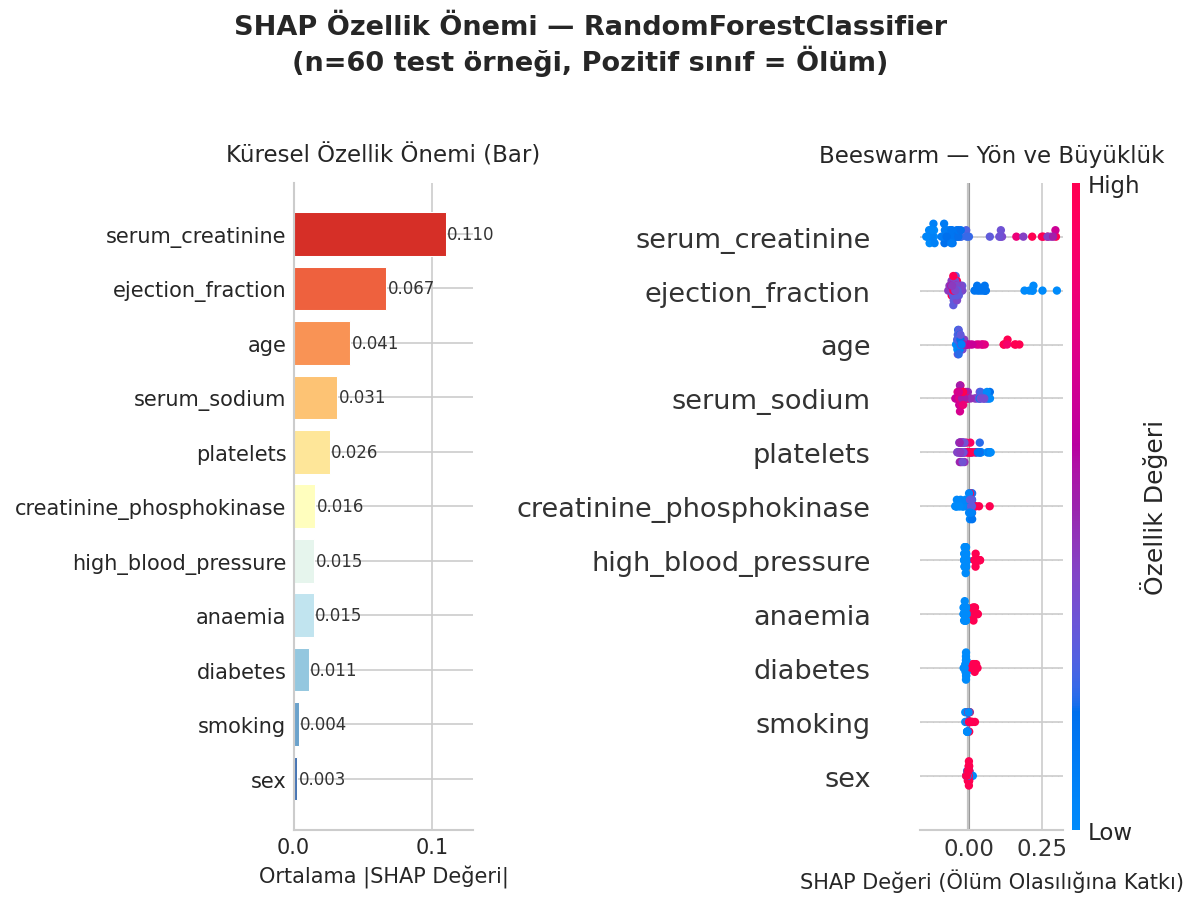


💾 Kaydedildi: /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB05_shap_summary.pdf

SHAP Özellik Sıralaması:
                 feature  mean_shap  shap_rank
        serum_creatinine   0.109806          1
       ejection_fraction   0.066668          2
                     age   0.040966          3
            serum_sodium   0.031475          4
               platelets   0.025918          5
creatinine_phosphokinase   0.015603          6
     high_blood_pressure   0.015024          7
                 anaemia   0.014511          8
                diabetes   0.010974          9
                 smoking   0.003786         10
                     sex   0.002754         11


In [9]:
# ============================================================
# HÜCRE 6: SHAP Summary Plot — Küresel Özellik Önemi
# İki panel: Bar (önem sırası) + Beeswarm (yön ve büyüklük)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(
    f'SHAP Özellik Önemi — {MODEL_TYPE}\n'
    f'(n={SHAP_N:,} test örneği, Pozitif sınıf = Ölüm)',
    fontsize=13, fontweight='bold', y=1.02
)

# ── Panel 1: Bar plot — mean |SHAP| ──────────────────────
ax1 = axes[0]
mean_shap = np.abs(sv).mean(axis=0)
feat_names = list(X_shap_ready.columns) if hasattr(X_shap_ready, 'columns') \
             else model_features

shap_df = pd.DataFrame({
    'feature'  : feat_names,
    'mean_shap': mean_shap
}).sort_values('mean_shap', ascending=True)

# Renk gradyanı — önem sırasına göre
colors = plt.cm.RdYlBu_r(np.linspace(0.1, 0.9, len(shap_df)))
bars = ax1.barh(
    shap_df['feature'], shap_df['mean_shap'],
    color=colors, edgecolor='white', linewidth=0.5
)

# Değer etiketleri
for bar, val in zip(bars, shap_df['mean_shap']):
    ax1.text(
        val + 0.001, bar.get_y() + bar.get_height() / 2,
        f'{val:.3f}', va='center', fontsize=8, color='#333'
    )

ax1.set_xlabel('Ortalama |SHAP Değeri|', fontsize=10)
ax1.set_title('Küresel Özellik Önemi (Bar)', fontsize=11, pad=10)
ax1.axvline(0, color='gray', linewidth=0.8)
ax1.set_xlim(0, shap_df['mean_shap'].max() * 1.18)

# ── Panel 2: Beeswarm plot (shap kütüphanesi) ────────────
ax2 = axes[1]
plt.sca(ax2)

# X_shap_ready DataFrame ise direkt kullan, değilse dönüştür
X_for_beeswarm = X_shap_ready if hasattr(X_shap_ready, 'columns') \
                 else pd.DataFrame(X_shap_ready, columns=feat_names)

shap.summary_plot(
    sv,
    X_for_beeswarm,
    plot_type='dot',
    show=False,
    max_display=11,
    color_bar_label='Özellik Değeri',
)
ax2.set_title('Beeswarm — Yön ve Büyüklük', fontsize=11, pad=10)
ax2.set_xlabel('SHAP Değeri (Ölüm Olasılığına Katkı)', fontsize=10)

plt.tight_layout()
out_path = FIGURES_DIR / 'NB05_shap_summary.pdf'
fig.savefig(out_path, dpi=SAVE_DPI, bbox_inches='tight')
plt.show()
print(f'\n💾 Kaydedildi: {out_path}')

# ── SHAP sıralamasını DataFrame'e dönüştür (Borda için) ──
shap_ranking = shap_df.sort_values('mean_shap', ascending=False).reset_index(drop=True)
shap_ranking['shap_rank'] = shap_ranking.index + 1
print('\nSHAP Özellik Sıralaması:')
print(shap_ranking[['feature', 'mean_shap', 'shap_rank']].to_string(index=False))

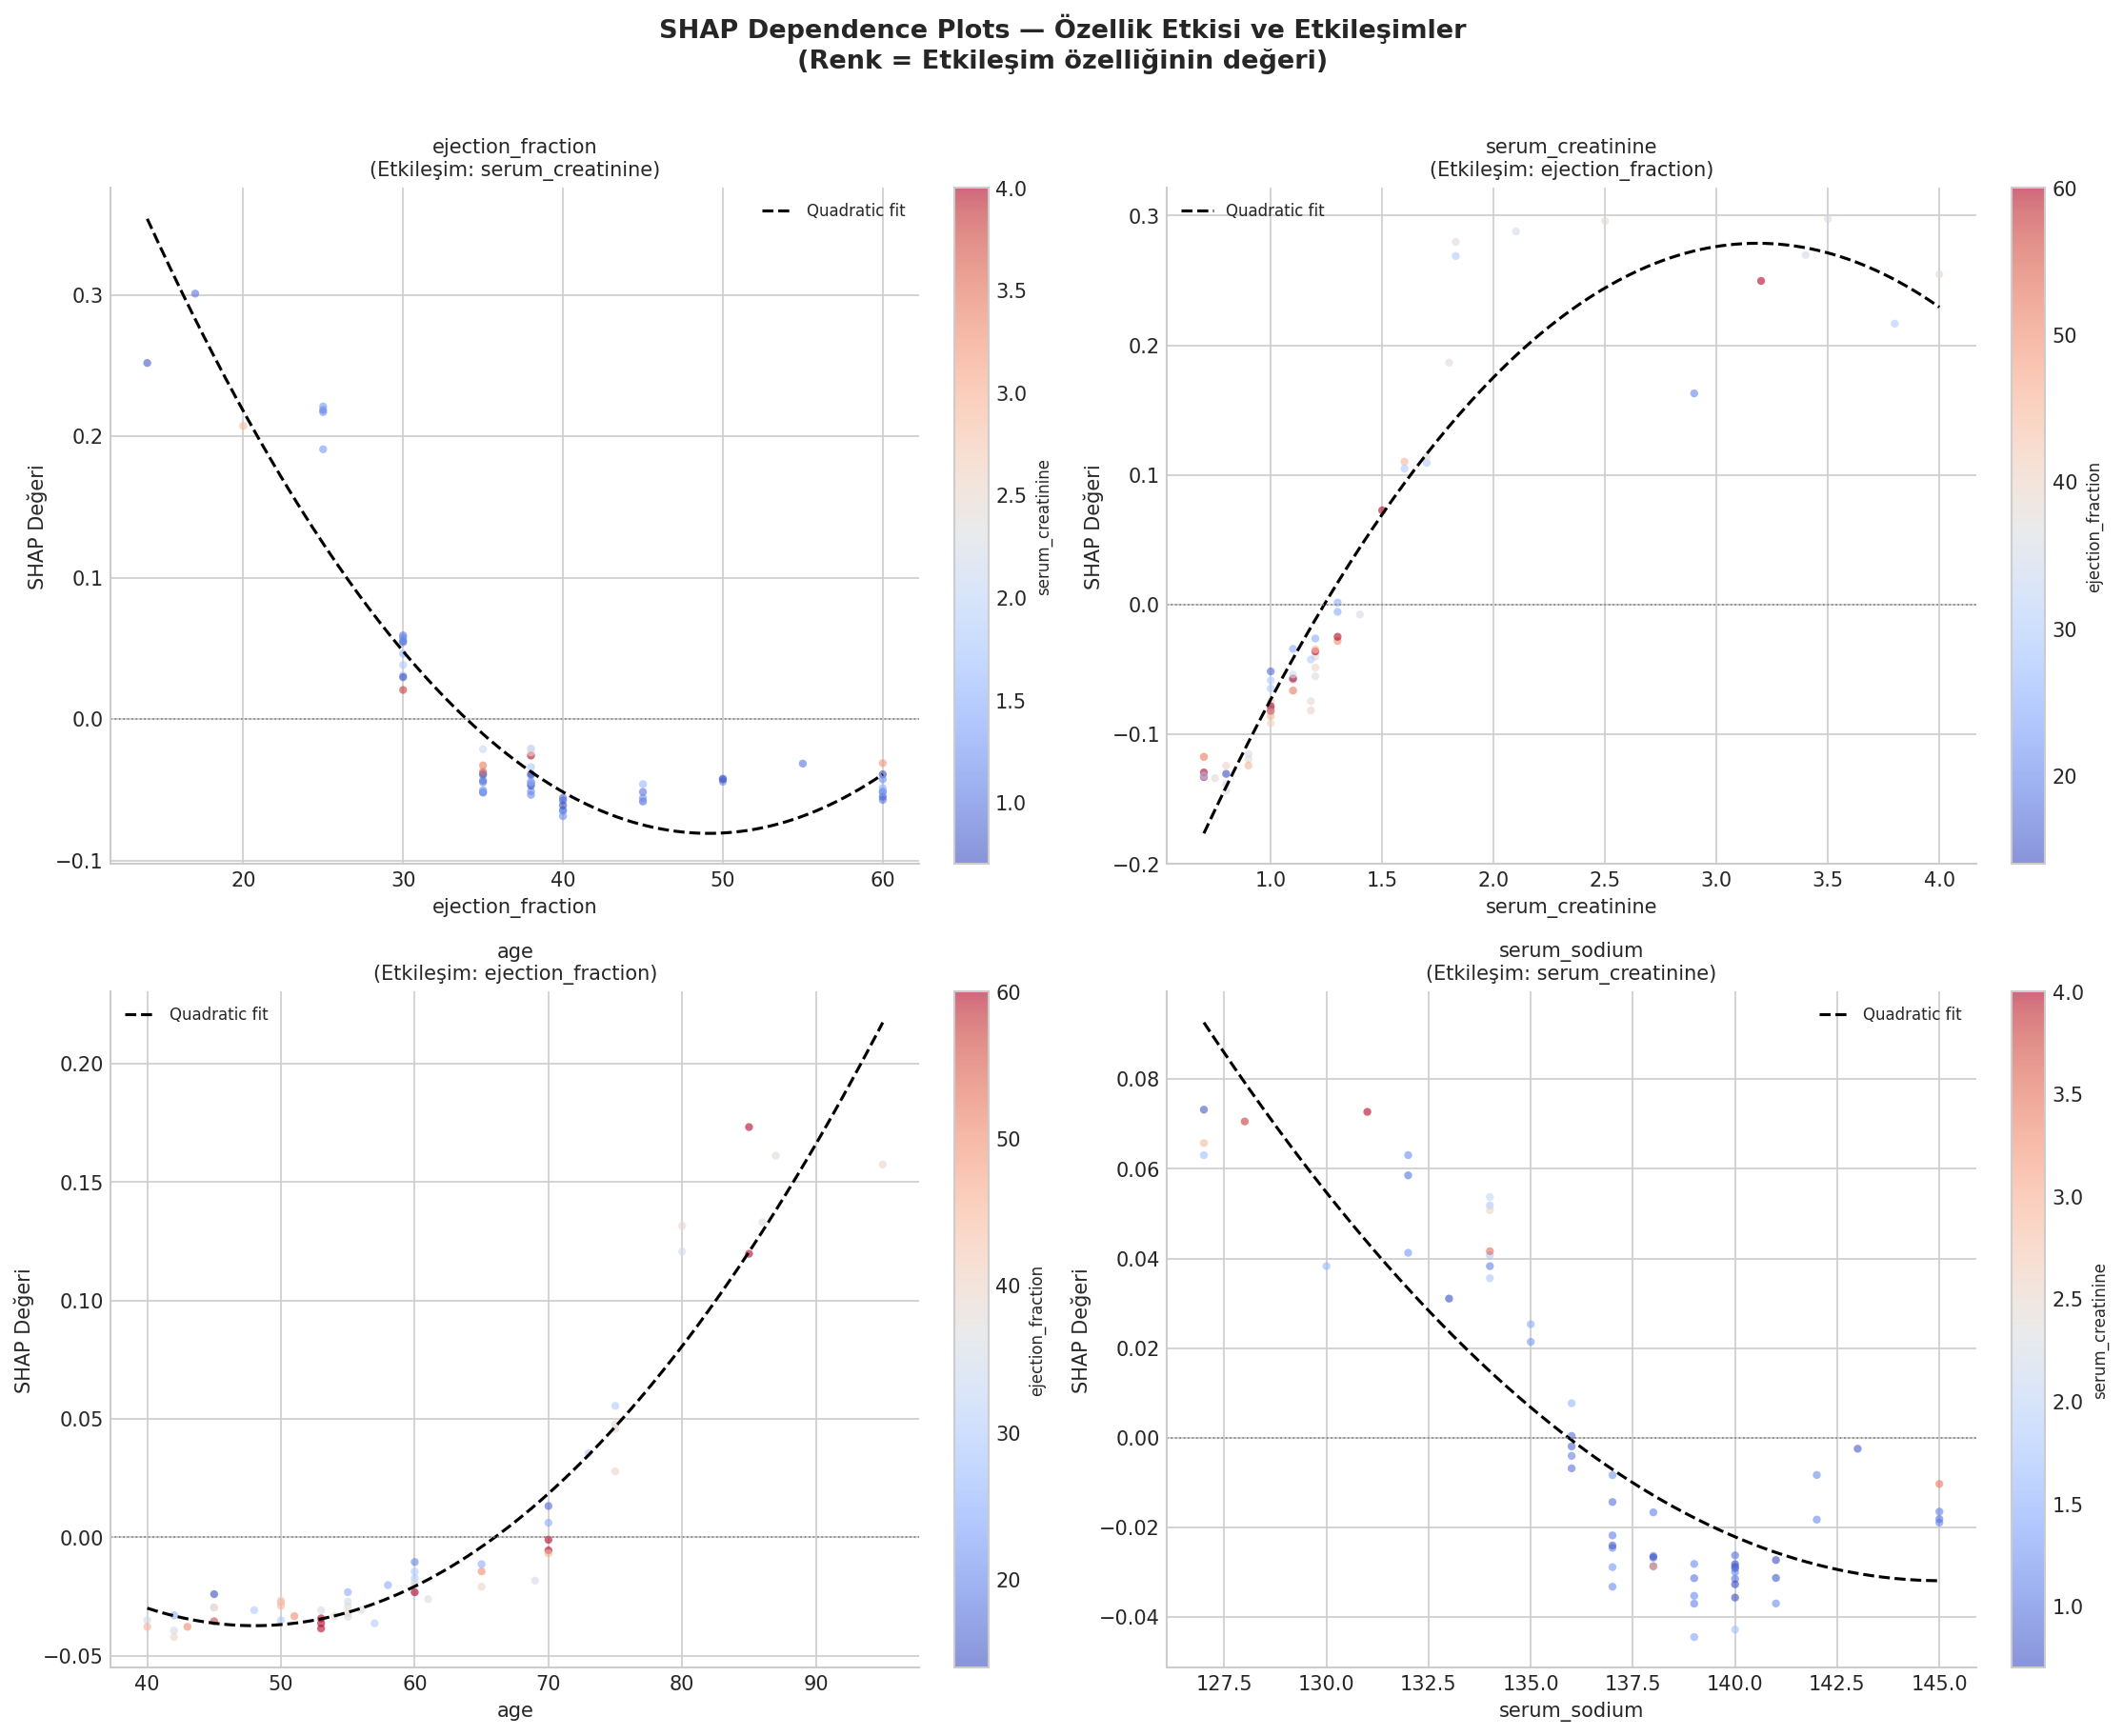

💾 Kaydedildi: /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB05_shap_dependence.pdf


In [10]:
# ============================================================
# HÜCRE 7: SHAP Dependence Plots
# EF ve Serum Creatinine — en güçlü iki özellik
# İnteraksiyon efektini de göster (renkli nokta)
# ============================================================

# Özellik indekslerini al
def feat_idx(name):
    if hasattr(X_for_beeswarm, 'columns'):
        return list(X_for_beeswarm.columns).index(name)
    return feat_names.index(name)

TARGET_FEATS = [
    ('ejection_fraction',    'serum_creatinine'),   # EF — etkileşim: creatinine
    ('serum_creatinine',     'ejection_fraction'),  # Creatinine — etkileşim: EF
    ('age',                  'ejection_fraction'),  # Yaş — etkileşim: EF
    ('serum_sodium',         'serum_creatinine'),   # Sodyum — etkileşim: creatinine
]

fig, axes = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle(
    'SHAP Dependence Plots — Özellik Etkisi ve Etkileşimler\n'
    '(Renk = Etkileşim özelliğinin değeri)',
    fontsize=13, fontweight='bold', y=1.01
)
axes_flat = axes.flatten()

X_arr = X_for_beeswarm.values if hasattr(X_for_beeswarm, 'values') \
        else np.array(X_for_beeswarm)

for idx_plot, (main_feat, interaction_feat) in enumerate(TARGET_FEATS):
    ax = axes_flat[idx_plot]
    try:
        mi  = feat_idx(main_feat)
        ii  = feat_idx(interaction_feat)
        x_vals = X_arr[:, mi]
        i_vals = X_arr[:, ii]

        # Renk ölçeği
        scatter = ax.scatter(
            x_vals, sv[:, mi],
            c=i_vals, cmap='coolwarm',
            alpha=0.6, s=16, linewidths=0
        )
        cb = plt.colorbar(scatter, ax=ax, fraction=0.04, pad=0.04)
        cb.set_label(interaction_feat, fontsize=8)

        # Trend çizgisi (LOWESS benzeri — polyfit)
        order = np.argsort(x_vals)
        z = np.polyfit(x_vals, sv[:, mi], 2)
        p = np.poly1d(z)
        x_line = np.linspace(x_vals.min(), x_vals.max(), 200)
        ax.plot(x_line, p(x_line), 'k--', linewidth=1.5, label='Quadratic fit')

        ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')
        ax.set_xlabel(main_feat, fontsize=10)
        ax.set_ylabel('SHAP Değeri', fontsize=10)
        ax.set_title(f'{main_feat}\n(Etkileşim: {interaction_feat})', fontsize=10)
        ax.legend(fontsize=8)

    except (ValueError, IndexError) as e:
        ax.text(0.5, 0.5, f'Özellik bulunamadı:\n{main_feat}',
                ha='center', va='center', transform=ax.transAxes, fontsize=9)
        ax.set_title(main_feat, fontsize=10)

plt.tight_layout()
out_path = FIGURES_DIR / 'NB05_shap_dependence.pdf'
fig.savefig(out_path, dpi=SAVE_DPI, bbox_inches='tight')
plt.show()
print(f'💾 Kaydedildi: {out_path}')

4 ÖRNEK HASTA — SHAP FORCE PLOTS

Doğru Pozitif (TP) — Yüksek Riskli Ölüm
  Gerçek etiket   : Ölüm
  Model tahmini   : 0.815 (Ölüm)


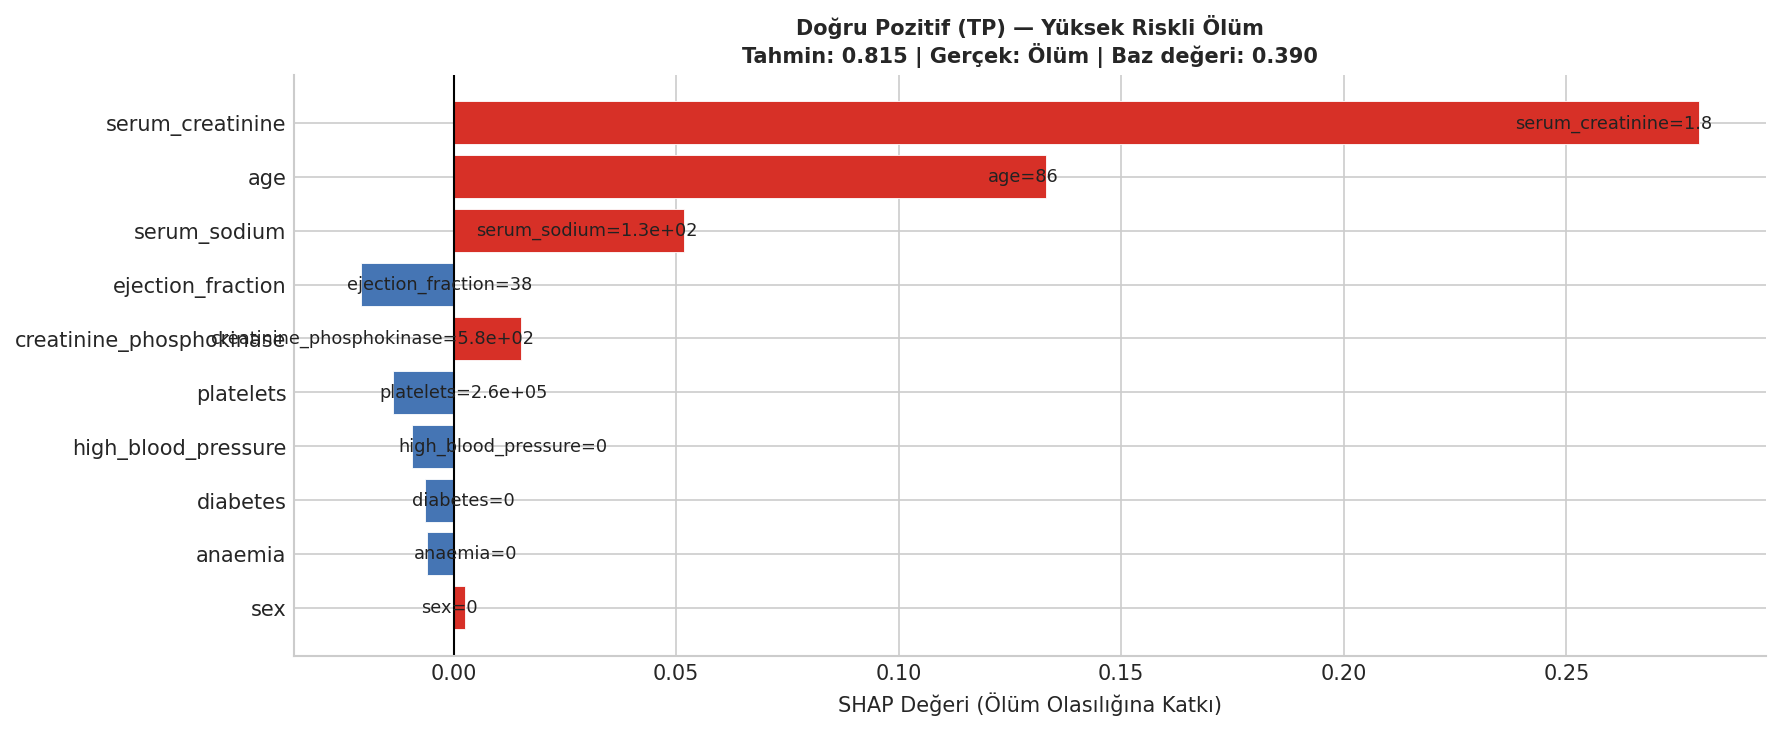

   💾 Kaydedildi: NB05_shap_force_TP.pdf

Doğru Negatif (TN) — Düşük Riskli Yaşayan
  Gerçek etiket   : Yaşayan
  Model tahmini   : 0.098 (Yaşayan)


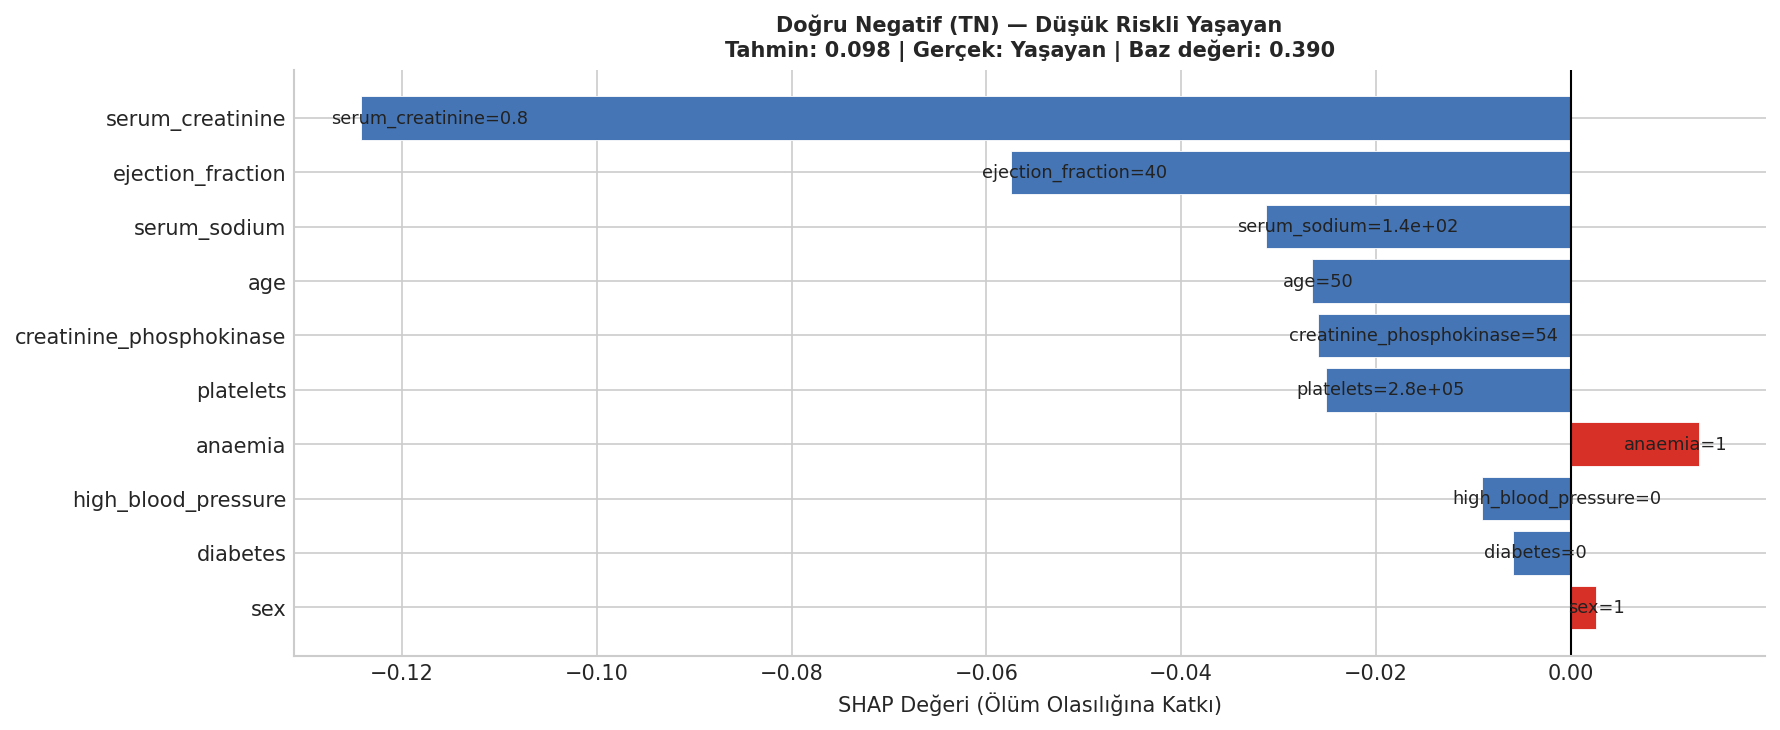

   💾 Kaydedildi: NB05_shap_force_TN.pdf

Sınır Vaka — Belirsiz Tahmin (p≈0.50)
  Gerçek etiket   : Ölüm
  Model tahmini   : 0.509 (Ölüm)


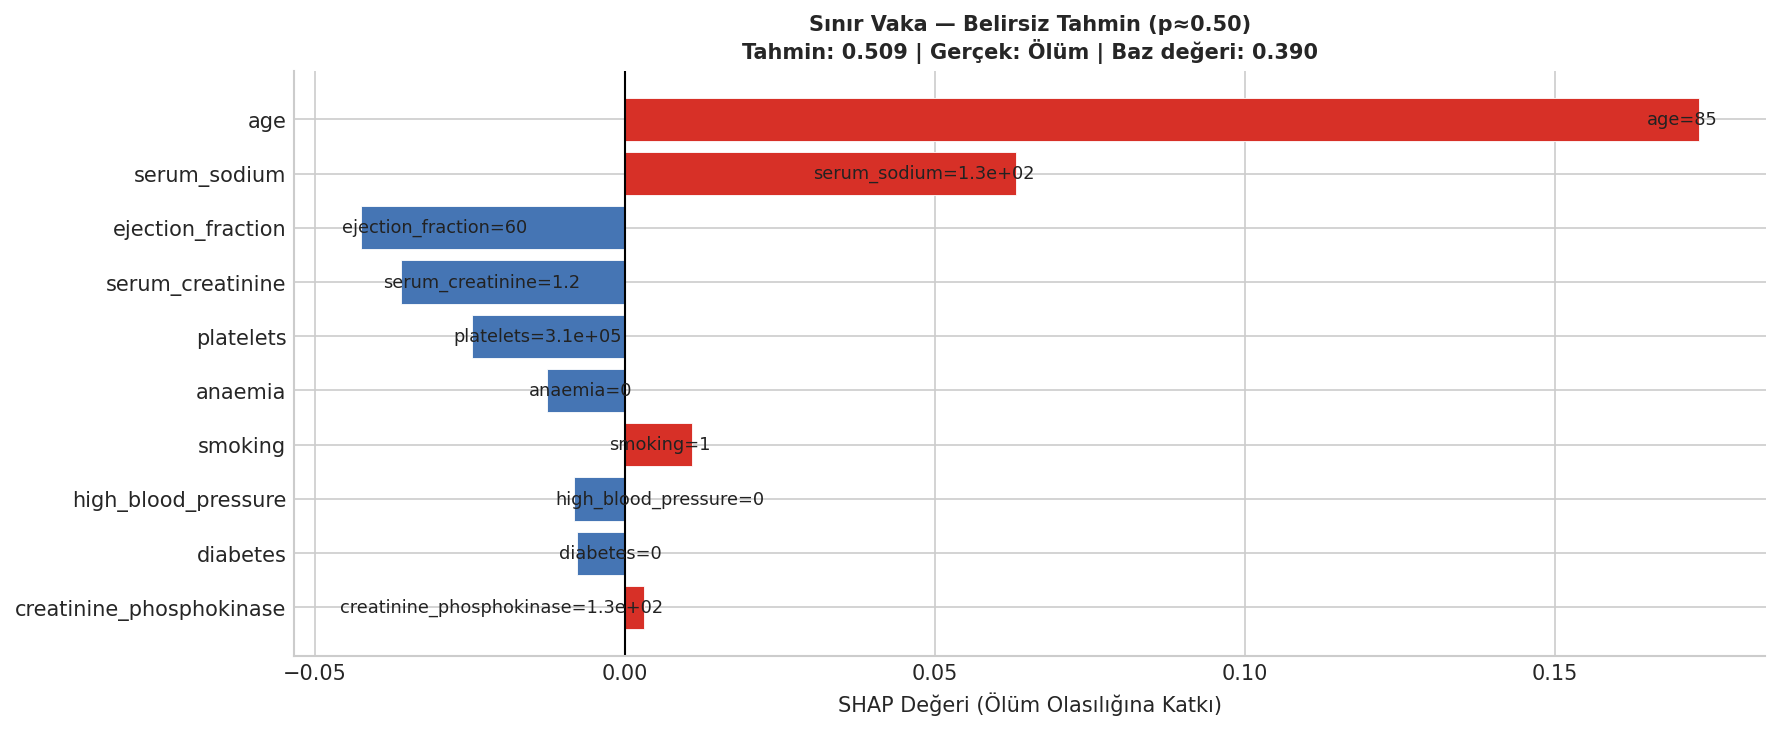

   💾 Kaydedildi: NB05_shap_force_p≈0.50.pdf

Yanlış Sınıflama (FP veya FN)
  Gerçek etiket   : Yaşayan
  Model tahmini   : 0.850 (Ölüm)


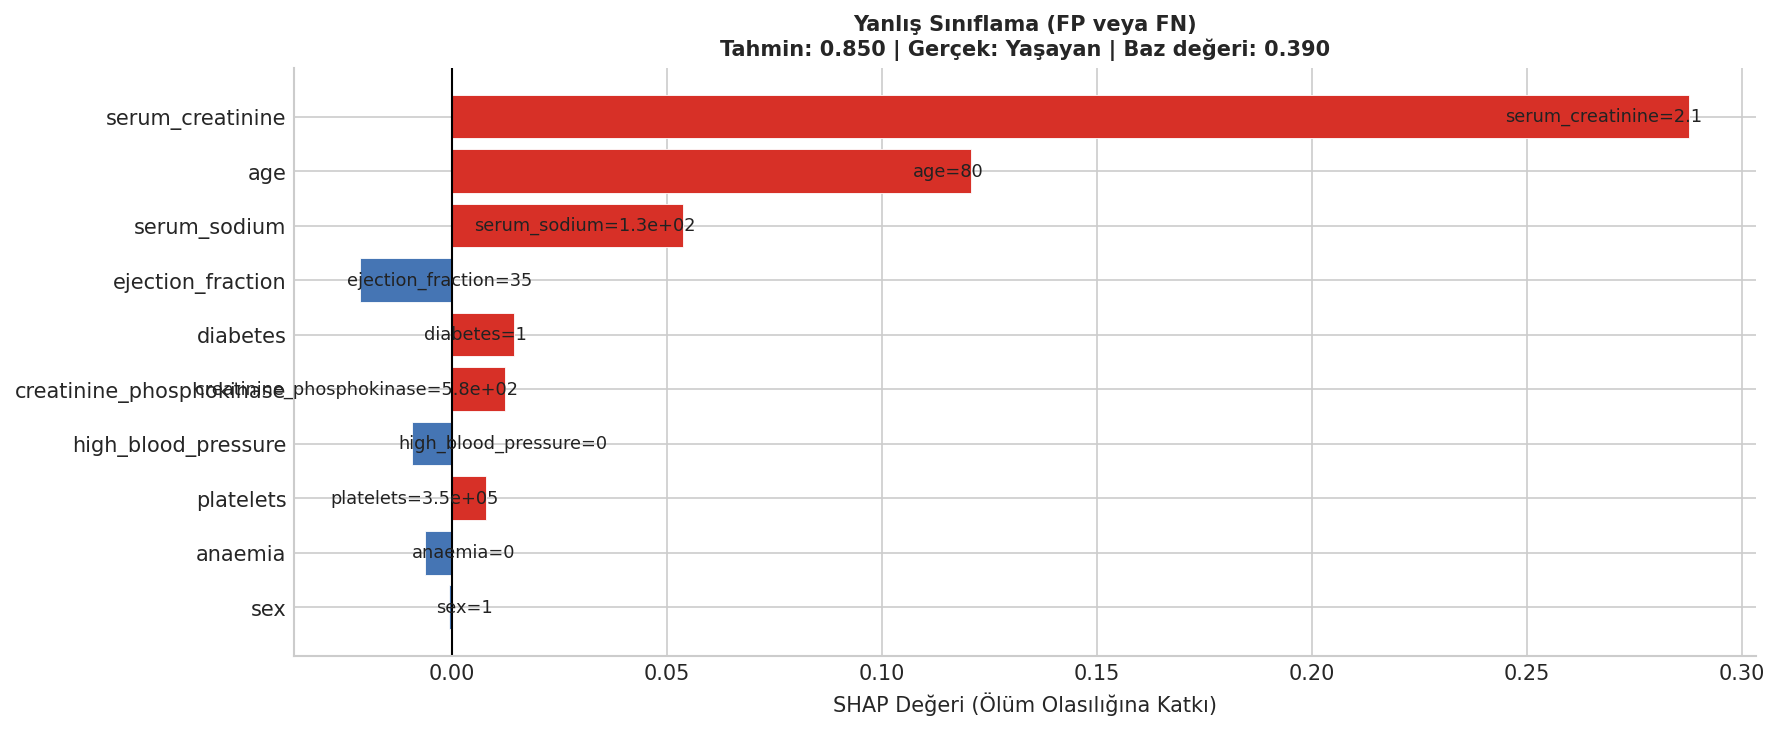

   💾 Kaydedildi: NB05_shap_force_FP_veya_FN.pdf


In [11]:
# ============================================================
# HÜCRE 8: SHAP Force Plots — 4 Örnek Hasta
# 1) Yüksek riskli — doğru pozitif (ölüm, model bildi)
# 2) Düşük riskli  — doğru negatif (yaşayan, model bildi)
# 3) Sınır vaka    — tahmin ≈ 0.5, model kararsız
# 4) Yanlış sınıflandırma — FP veya FN
# ============================================================

print('4 ÖRNEK HASTA — SHAP FORCE PLOTS')
print('=' * 60)

# Vaka seçimi
def find_case(y_true, y_prob, y_pred, case_type='tp', margin=0.05):
    """Belirli tipte vakaları sırala ve en temsili olanı döndür."""
    if case_type == 'tp':
        mask = (y_true == 1) & (y_pred == 1)
        return np.where(mask)[0][np.argmax(y_prob[mask])] if mask.any() else None
    elif case_type == 'tn':
        mask = (y_true == 0) & (y_pred == 0)
        return np.where(mask)[0][np.argmin(y_prob[mask])] if mask.any() else None
    elif case_type == 'borderline':
        dists = np.abs(y_prob - 0.5)
        return int(np.argmin(dists))
    elif case_type == 'fp':
        mask = (y_true == 0) & (y_pred == 1)
        return np.where(mask)[0][np.argmax(y_prob[mask])] if mask.any() else None
    elif case_type == 'fn':
        mask = (y_true == 1) & (y_pred == 0)
        return np.where(mask)[0][np.argmin(y_prob[mask])] if mask.any() else None
    return None

y_pred_shap = (y_prob_sh >= 0.5).astype(int)

# FP veya FN varsa birini seç
fp_idx = find_case(y_shap, y_prob_sh, y_pred_shap, 'fp')
fn_idx = find_case(y_shap, y_prob_sh, y_pred_shap, 'fn')
wrong_idx = fp_idx if fp_idx is not None else fn_idx

cases = [
    ('Doğru Pozitif (TP) — Yüksek Riskli Ölüm',  find_case(y_shap, y_prob_sh, y_pred_shap, 'tp')),
    ('Doğru Negatif (TN) — Düşük Riskli Yaşayan', find_case(y_shap, y_prob_sh, y_pred_shap, 'tn')),
    ('Sınır Vaka — Belirsiz Tahmin (p≈0.50)',      find_case(y_shap, y_prob_sh, y_pred_shap, 'borderline')),
    ('Yanlış Sınıflama (FP veya FN)',              wrong_idx),
]

feat_names_list = list(X_for_beeswarm.columns) if hasattr(X_for_beeswarm, 'columns') \
                 else feat_names

for case_title, case_idx in cases:
    if case_idx is None:
        print(f'⚠️  {case_title}: Bu tipte vaka bulunamadı.')
        continue

    patient_data  = X_arr[case_idx]
    patient_shap  = sv[case_idx]
    patient_prob  = y_prob_sh[case_idx]
    patient_true  = y_shap[case_idx]

    print(f'\n{case_title}')
    print(f'  Gerçek etiket   : {"Ölüm" if patient_true == 1 else "Yaşayan"}')
    print(f'  Model tahmini   : {patient_prob:.3f} ({"Ölüm" if patient_prob >= 0.5 else "Yaşayan"})')

    # Waterfall plot (force plot'un daha okunabilir alternatifi)
    fig, ax = plt.subplots(figsize=(12, 5))

    # Özellikleri SHAP büyüklüğüne göre sırala
    order    = np.argsort(np.abs(patient_shap))[::-1][:10]  # top-10
    features = [feat_names_list[i] for i in order]
    values   = patient_shap[order]
    raw_vals = patient_data[order]

    # Yatay bar — pozitif: kırmızı (ölüm riskini artırır), negatif: mavi
    colors_bar = [PALETTE['shap_pos'] if v > 0 else PALETTE['shap_neg'] for v in values]
    ax.barh(
        features[::-1], values[::-1],
        color=colors_bar[::-1], edgecolor='white', linewidth=0.4
    )
    # Ham değer etiketleri
    for i, (feat, v, rv) in enumerate(zip(features[::-1], values[::-1], raw_vals[::-1])):
        ha = 'left' if v < 0 else 'right'
        xpos = v + (0.003 if v >= 0 else -0.003)
        ax.text(xpos, i, f'{feat}={rv:.2g}', va='center',
                ha=ha, fontsize=8.5, color='#222')

    ax.axvline(0, color='black', linewidth=1)
    ax.set_xlabel('SHAP Değeri (Ölüm Olasılığına Katkı)', fontsize=10)
    ax.set_title(
        f'{case_title}\n'
        f'Tahmin: {patient_prob:.3f} | Gerçek: {"Ölüm" if patient_true==1 else "Yaşayan"} | '
        f'Baz değeri: {expected_value:.3f}',
        fontsize=10, fontweight='bold'
    )

    plt.tight_layout()
    safe_name = case_title.split('(')[1].split(')')[0].strip().replace(' ', '_') \
                if '(' in case_title else str(case_idx)
    out_path = FIGURES_DIR / f'NB05_shap_force_{safe_name}.pdf'
    fig.savefig(out_path, dpi=SAVE_DPI, bbox_inches='tight')
    plt.show()
    print(f'   💾 Kaydedildi: {out_path.name}')

BORDA AGGREGATE RANKING KARŞILAŞTIRMASI
Spearman ρ (Chicco vs SHAP): 0.973  (p=0.0000)
✅ Güçlü korelasyon — SHAP sıralaması Chicco ile uyuşuyor

                 Özellik  Chicco_Borda_Rank  SHAP_Rank  Fark  Mean_SHAP
        serum_creatinine                  1          1     0     0.1098
       ejection_fraction                  2          2     0     0.0667
                     age                  3          3     0     0.0410
            serum_sodium                  4          4     0     0.0315
               platelets                  6          5    -1     0.0259
creatinine_phosphokinase                  5          6     1     0.0156
     high_blood_pressure                  8          7    -1     0.0150
                 anaemia                  7          8     1     0.0145
                diabetes                  9          9     0     0.0110
                 smoking                 11         10    -1     0.0038
                     sex                 10         11     1   

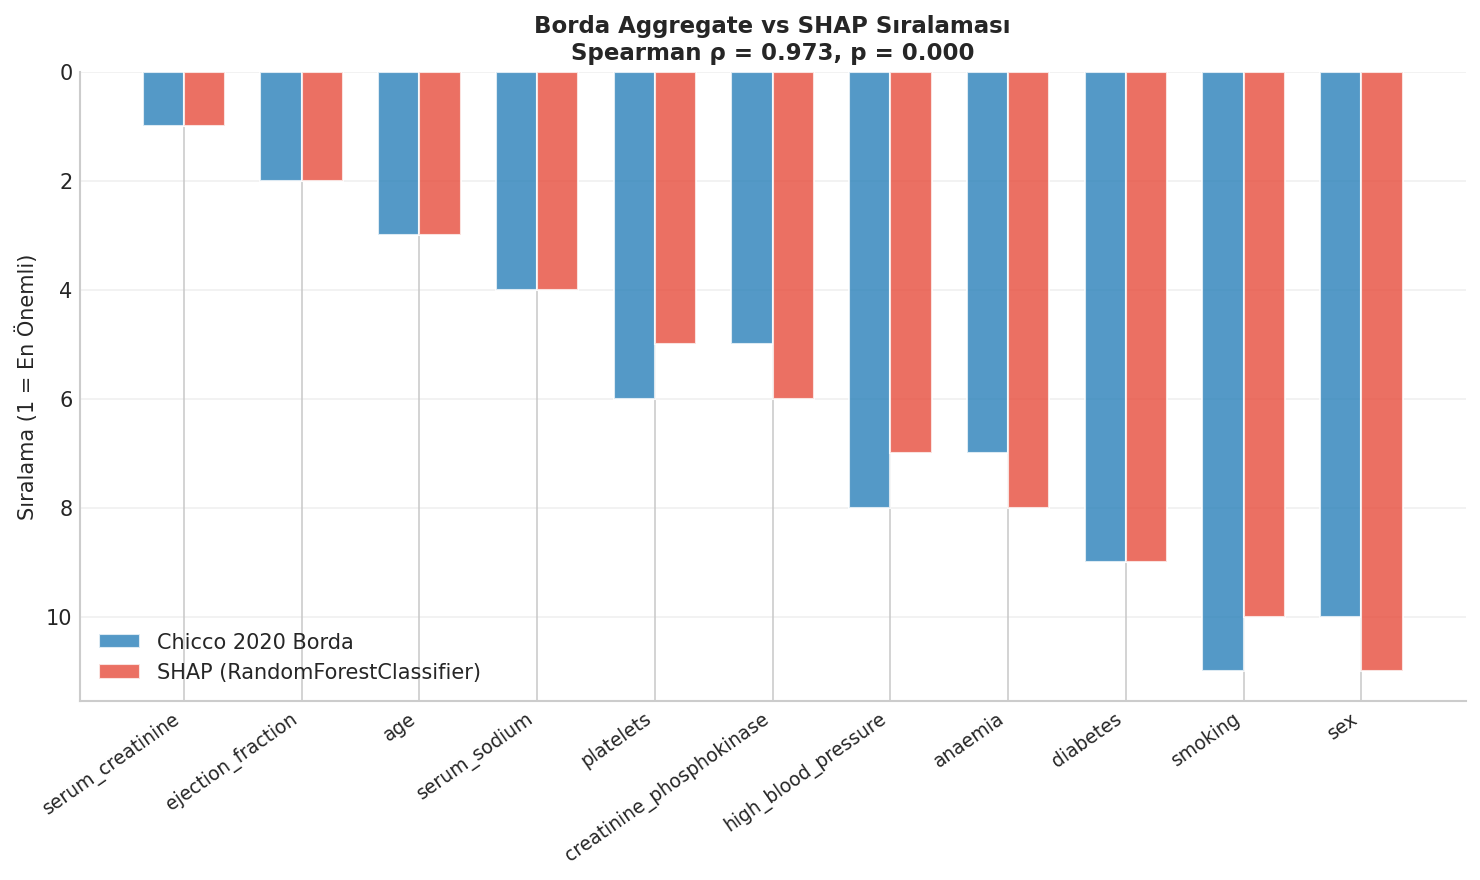

💾 Kaydedildi: /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB05_borda_comparison.pdf


In [12]:
# ============================================================
# HÜCRE 9: Borda Aggregate Ranking Karşılaştırması
# Chicco & Jurman (2020) — Table 4 sıralamasıyla kıyasla
# Ref: https://doi.org/10.1186/s12911-020-1023-5
# ============================================================

print('BORDA AGGREGATE RANKING KARŞILAŞTIRMASI')
print('=' * 60)

# Chicco 2020 — Borda aggregate ranking (Table 4, S2 senaryosu)
# Sıralama 1 = en önemli özellik (düşük rank = yüksek önem)
CHICCO_BORDA_RANK = {
    'serum_creatinine'       : 1,
    'ejection_fraction'      : 2,
    'age'                    : 3,
    'serum_sodium'           : 4,
    'creatinine_phosphokinase': 5,
    'platelets'              : 6,
    'anaemia'                : 7,
    'high_blood_pressure'    : 8,
    'diabetes'               : 9,
    'sex'                    : 10,
    'smoking'                : 11,
}

# SHAP sıralaması (Hücre 6'dan)
shap_rank_dict = dict(zip(
    shap_ranking['feature'],
    shap_ranking['shap_rank']
))

# Birleştir
comparison_rows = []
for feat in KAGGLE_FEATURES_S2:
    chicco_r = CHICCO_BORDA_RANK.get(feat, np.nan)
    shap_r   = shap_rank_dict.get(feat, np.nan)
    diff     = shap_r - chicco_r if not np.isnan(chicco_r) and not np.isnan(shap_r) else np.nan
    mean_shap_val = float(shap_ranking.loc[
        shap_ranking['feature'] == feat, 'mean_shap'
    ].values[0]) if feat in shap_ranking['feature'].values else np.nan

    comparison_rows.append({
        'Özellik'          : feat,
        'Chicco_Borda_Rank': chicco_r,
        'SHAP_Rank'        : shap_r,
        'Fark'             : diff,
        'Mean_SHAP'        : round(mean_shap_val, 4) if not np.isnan(mean_shap_val) else np.nan
    })

df_borda = pd.DataFrame(comparison_rows).sort_values('SHAP_Rank')

# Spearman korelasyonu
mask = df_borda['Chicco_Borda_Rank'].notna() & df_borda['SHAP_Rank'].notna()
rho, p_val = stats.spearmanr(
    df_borda.loc[mask, 'Chicco_Borda_Rank'],
    df_borda.loc[mask, 'SHAP_Rank']
)
print(f'Spearman ρ (Chicco vs SHAP): {rho:.3f}  (p={p_val:.4f})')
if rho > 0.7:
    print('✅ Güçlü korelasyon — SHAP sıralaması Chicco ile uyuşuyor')
elif rho > 0.4:
    print('ℹ️  Orta korelasyon — Bazı özellikler farklı sıralamalarda')
else:
    print('⚠️  Zayıf korelasyon — Metodoloji farkı beklenen bir bulgudur')

print()
print(df_borda.to_string(index=False))

# Kaydet
df_borda['Spearman_rho'] = rho
df_borda['Spearman_p']   = p_val
csv_path = RESULTS_DIR / 'NB05_borda_comparison.csv'
df_borda.to_csv(csv_path, index=False)
print(f'\n💾 Kaydedildi: {csv_path}')

# ── Görselleştirme: Sıralama karşılaştırması ────────────
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(df_borda))
width = 0.35

ax.bar(x - width/2, df_borda['Chicco_Borda_Rank'], width,
       label='Chicco 2020 Borda', color='#2980B9', alpha=0.8, edgecolor='white')
ax.bar(x + width/2, df_borda['SHAP_Rank'], width,
       label=f'SHAP ({MODEL_TYPE})', color='#E74C3C', alpha=0.8, edgecolor='white')

# Fark okları
for i, (_, row) in enumerate(df_borda.iterrows()):
    if not np.isnan(row['Fark']) and abs(row['Fark']) >= 2:
        ax.annotate(
            '', xy=(i + width/2, row['SHAP_Rank']),
            xytext=(i - width/2, row['Chicco_Borda_Rank']),
            arrowprops=dict(arrowstyle='->', color='#555', lw=1.2)
        )

ax.set_xticks(x)
ax.set_xticklabels(df_borda['Özellik'], rotation=35, ha='right', fontsize=9)
ax.set_ylabel('Sıralama (1 = En Önemli)', fontsize=10)
ax.set_title(
    f'Borda Aggregate vs SHAP Sıralaması\n'
    f'Spearman ρ = {rho:.3f}, p = {p_val:.3f}',
    fontsize=11, fontweight='bold'
)
ax.invert_yaxis()  # 1 en üstte olsun
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
out_path = FIGURES_DIR / 'NB05_borda_comparison.pdf'
fig.savefig(out_path, dpi=SAVE_DPI, bbox_inches='tight')
plt.show()
print(f'💾 Kaydedildi: {out_path}')

---
## BÖLÜM B: Adalet (Fairness) Analizi

**Alt Gruplar:**
- Cinsiyet: Kadın (sex=0) / Erkek (sex=1)  
- Yaş: Genç (<65) / Yaşlı (≥65)  
- Kesişimsel: Genç-Erkek / Genç-Kadın / Yaşlı-Erkek / Yaşlı-Kadın

**Metrikler:**
1. **C-index (AUC)** — her grupta ayrı, 95% CI (bootstrap)
2. **Demographic Parity Difference** — gruplar arası pozitif tahmin oranı farkı
3. **Equalized Odds Difference** — gruplar arası TPR/FPR farkı
4. **Brier Skoru** — kalibrasyon başarısı (düşük = iyi)

> **Yorum:** Alt grup n<30 ise CI çok geniş olur — raporlama.
> Kaggle veri seti küçük (n≈299 test), bu nedenle bazı alt gruplarda n<30 olabilir.
> MIMIC external validation kohortundan elde edilen fairness sonuçları daha güvenilirdir.

In [13]:
# ============================================================
# HÜCRE 10: Alt Grup C-index — Bootstrap 95% CI
# ============================================================

print('ALT GRUP C-INDEX ANALİZİ')
print('=' * 60)

# Test setine grup değişkenlerini ekle
df_eval = X_test_aligned.copy()
df_eval['y_true'] = y_test
df_eval['y_prob'] = y_prob
df_eval['y_pred'] = (y_prob >= 0.5).astype(int)
df_eval['age_group'] = (df_eval['age'] >= AGE_CUTOFF).map({True: f'≥{AGE_CUTOFF}', False: f'<{AGE_CUTOFF}'})
df_eval['sex_group'] = df_eval['sex'].map({1: 'Erkek', 0: 'Kadın'})
df_eval['intersect']  = df_eval['sex_group'] + ' + ' + df_eval['age_group']

def bootstrap_auc(y_true, y_score, n_boot=N_BOOTSTRAP, alpha=0.05):
    """Bootstrap ile AUC 95% CI hesapla."""
    rng = np.random.RandomState(42)
    auc_center = roc_auc_score(y_true, y_score)
    boot_aucs  = []
    for _ in range(n_boot):
        idx = rng.choice(len(y_true), len(y_true), replace=True)
        if len(np.unique(y_true[idx])) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_true[idx], y_score[idx]))
    if len(boot_aucs) < 50:
        return auc_center, np.nan, np.nan
    ci_lo = np.percentile(boot_aucs, 100 * alpha / 2)
    ci_hi = np.percentile(boot_aucs, 100 * (1 - alpha / 2))
    return auc_center, ci_lo, ci_hi

# Alt grupları tanımla
SUBGROUPS = [
    ('Tüm test seti',     df_eval),
    ('Erkek',             df_eval[df_eval['sex_group'] == 'Erkek']),
    ('Kadın',             df_eval[df_eval['sex_group'] == 'Kadın']),
    (f'Yaş <{AGE_CUTOFF}',    df_eval[df_eval['age_group'] == f'<{AGE_CUTOFF}']),
    (f'Yaş ≥{AGE_CUTOFF}',   df_eval[df_eval['age_group'] == f'≥{AGE_CUTOFF}']),
    (f'Erkek + Yaş <{AGE_CUTOFF}',  df_eval[df_eval['intersect'] == f'Erkek + <{AGE_CUTOFF}']),
    (f'Erkek + Yaş ≥{AGE_CUTOFF}', df_eval[df_eval['intersect'] == f'Erkek + ≥{AGE_CUTOFF}']),
    (f'Kadın + Yaş <{AGE_CUTOFF}',  df_eval[df_eval['intersect'] == f'Kadın + <{AGE_CUTOFF}']),
    (f'Kadın + Yaş ≥{AGE_CUTOFF}', df_eval[df_eval['intersect'] == f'Kadın + ≥{AGE_CUTOFF}']),
]

fairness_rows = []
MIN_SUBGROUP_N = 30  # Bu altındaki grupları işaretle

for group_name, df_sub in SUBGROUPS:
    n = len(df_sub)
    n_pos = df_sub['y_true'].sum()
    n_neg = n - n_pos
    warn  = '⚠️' if n < MIN_SUBGROUP_N else ''

    if n < 10 or n_pos == 0 or n_neg == 0:
        row = dict(group=group_name, n=n, n_death=n_pos,
                   auc=np.nan, ci_lo=np.nan, ci_hi=np.nan,
                   mcc=np.nan, f1=np.nan, note='Yeterli vaka yok')
    else:
        auc_c, ci_lo, ci_hi = bootstrap_auc(
            df_sub['y_true'].values, df_sub['y_prob'].values
        )
        mcc_g = matthews_corrcoef(df_sub['y_true'], df_sub['y_pred'])
        f1_g  = f1_score(df_sub['y_true'], df_sub['y_pred'], zero_division=0)
        row = dict(group=group_name, n=n, n_death=int(n_pos),
                   auc=round(auc_c, 4), ci_lo=round(ci_lo, 4), ci_hi=round(ci_hi, 4),
                   mcc=round(mcc_g, 4), f1=round(f1_g, 4), note=warn)

    fairness_rows.append(row)
    ci_str = f'[{ci_lo:.3f}–{ci_hi:.3f}]' if not np.isnan(ci_lo) else '[N/A]'
    print(f'{warn}{group_name:<35} n={n:>4} | Death={int(n_pos):>3} | '
          f'AUC={row["auc"]:.3f} {ci_str} | MCC={row["mcc"]:.3f}')

df_fairness = pd.DataFrame(fairness_rows)
csv_path = RESULTS_DIR / 'NB05_fairness_metrics.csv'
df_fairness.to_csv(csv_path, index=False)
print(f'\n💾 Kaydedildi: {csv_path}')

ALT GRUP C-INDEX ANALİZİ
Tüm test seti                       n=  60 | Death= 19 | AUC=0.787 [0.648–0.889] | MCC=0.402
Erkek                               n=  41 | Death= 12 | AUC=0.767 [0.603–0.909] | MCC=0.402
⚠️Kadın                               n=  19 | Death=  7 | AUC=0.845 [0.633–1.000] | MCC=0.420
Yaş <65                             n=  39 | Death=  7 | AUC=0.817 [0.622–0.971] | MCC=0.537
⚠️Yaş ≥65                             n=  21 | Death= 12 | AUC=0.593 [0.306–0.853] | MCC=0.028
⚠️Erkek + Yaş <65                     n=  27 | Death=  4 | AUC=0.761 [0.375–1.000] | MCC=0.467
⚠️Erkek + Yaş ≥65                     n=  14 | Death=  8 | AUC=0.625 [0.250–1.000] | MCC=0.125
⚠️Kadın + Yaş <65                     n=  12 | Death=  3 | AUC=0.963 [0.818–1.000] | MCC=0.775
⚠️Kadın + Yaş ≥65                     n=   7 | Death=  4 | AUC=nan [0.818–1.000] | MCC=nan

💾 Kaydedildi: /content/drive/MyDrive/HF_Revisit_Project/results/NB05_fairness_metrics.csv


In [14]:
# ============================================================
# HÜCRE 11: Fairlearn Metrikleri
# Demographic Parity + Equalized Odds — scikit-fairlearn
# ============================================================

print('FAIRLEARN METRİK ANALİZİ')
print('=' * 60)

def compute_fairlearn_metrics(df, sensitive_col, label='', threshold=0.5):
    """Belirli bir hassas özellik için fairlearn metriklerini hesapla."""
    y_true  = df['y_true'].values
    y_pred  = (df['y_prob'].values >= threshold).astype(int)
    groups  = df[sensitive_col].values

    if len(np.unique(groups)) < 2:
        print(f'  ⚠️  {label}: Grup çeşitliliği yok.')
        return {}

    results = {}

    # Demographic Parity Difference
    # Gruplar arası pozitif tahmin oranı farkı
    # 0 = mükemmel parité, |değer| büyük = eşitsizlik
    dpd = demographic_parity_difference(y_true, y_pred, sensitive_features=groups)
    results['dpd'] = round(float(dpd), 4)

    # Equalized Odds Difference
    # max(TPR farkı, FPR farkı)
    # 0 = eşit şans, |değer| büyük = ayrımcılık
    eod = equalized_odds_difference(y_true, y_pred, sensitive_features=groups)
    results['eod'] = round(float(eod), 4)

    # MetricFrame ile grup bazlı detay
    mf = MetricFrame(
        metrics={
            'AUC'         : lambda yt, yp: roc_auc_score(yt, yp) if len(np.unique(yt))>1 else np.nan,
            'Precision'   : lambda yt, yp: precision_score(yt, yp, zero_division=0),
            'Recall (TPR)': lambda yt, yp: recall_score(yt, yp, zero_division=0),
            'F1'          : lambda yt, yp: f1_score(yt, yp, zero_division=0),
            'MCC'         : matthews_corrcoef,
            'Sel. Rate'   : selection_rate,
        },
        y_true=y_true,
        y_pred=y_pred,
        sensitive_features=groups
    )
    results['metric_frame'] = mf

    print(f'\n  ── {label} ──')
    print(f'  Demographic Parity Difference : {dpd:+.4f}')
    print(f'  Equalized Odds Difference     : {eod:+.4f}')
    print(f'  Genel performans:')
    print(mf.overall.to_string())
    print(f'\n  Grup bazlı performans:')
    print(mf.by_group.to_string())

    return results

# Cinsiyet
sex_results = compute_fairlearn_metrics(
    df_eval, 'sex_group', label='Cinsiyet (Erkek/Kadın)'
)

# Yaş
age_results = compute_fairlearn_metrics(
    df_eval, 'age_group', label=f'Yaş (<{AGE_CUTOFF}/≥{AGE_CUTOFF})'
)

# Kesişimsel
intersect_results = compute_fairlearn_metrics(
    df_eval, 'intersect', label='Kesişimsel (4 grup)'
)

# Özet tablo
print('\n' + '='*60)
print('ÖZET TABLO — FAIRNESS METRİKLERİ')
print('='*60)
print(f'{"Boyut":<25} {"Dem. Parity Diff":>18} {"Eq. Odds Diff":>15}')
print('-'*60)
for label, res in [
    ('Cinsiyet', sex_results),
    (f'Yaş (<{AGE_CUTOFF}/≥{AGE_CUTOFF})', age_results),
    ('Kesişimsel', intersect_results)
]:
    dpd_val = res.get('dpd', np.nan)
    eod_val = res.get('eod', np.nan)
    dpd_str = f'{dpd_val:+.4f}' if not np.isnan(dpd_val) else 'N/A'
    eod_str = f'{eod_val:+.4f}' if not np.isnan(eod_val) else 'N/A'
    flag = '⚠️' if (abs(dpd_val) > 0.1 or abs(eod_val) > 0.1) \
                  and not np.isnan(dpd_val) else '✅'
    print(f'{label:<25} {dpd_str:>18} {eod_str:>15}  {flag}')
print('\n  ⚠️ = |fark| > 0.10 eşiği (IEEE fairness literatürü)'
      '\n  ✅ = Kabul edilebilir aralıkta')

FAIRLEARN METRİK ANALİZİ

  ── Cinsiyet (Erkek/Kadın) ──
  Demographic Parity Difference : +0.0501
  Equalized Odds Difference     : +0.0952
  Genel performans:
AUC             0.706033
Precision       0.571429
Recall (TPR)    0.631579
F1              0.600000
MCC             0.401878
Sel. Rate       0.350000

  Grup bazlı performans:
                          AUC  Precision  Recall (TPR)        F1       MCC  Sel. Rate
sensitive_feature_0                                                                  
Erkek                0.712644   0.533333      0.666667  0.592593  0.401735   0.365854
Kadın                0.702381   0.666667      0.571429  0.615385  0.420041   0.315789

  ── Yaş (<65/≥65) ──
  Demographic Parity Difference : +0.3407
  Equalized Odds Difference     : +0.4306
  Genel performans:
AUC             0.706033
Precision       0.571429
Recall (TPR)    0.631579
F1              0.600000
MCC             0.401878
Sel. Rate       0.350000

  Grup bazlı performans:
                

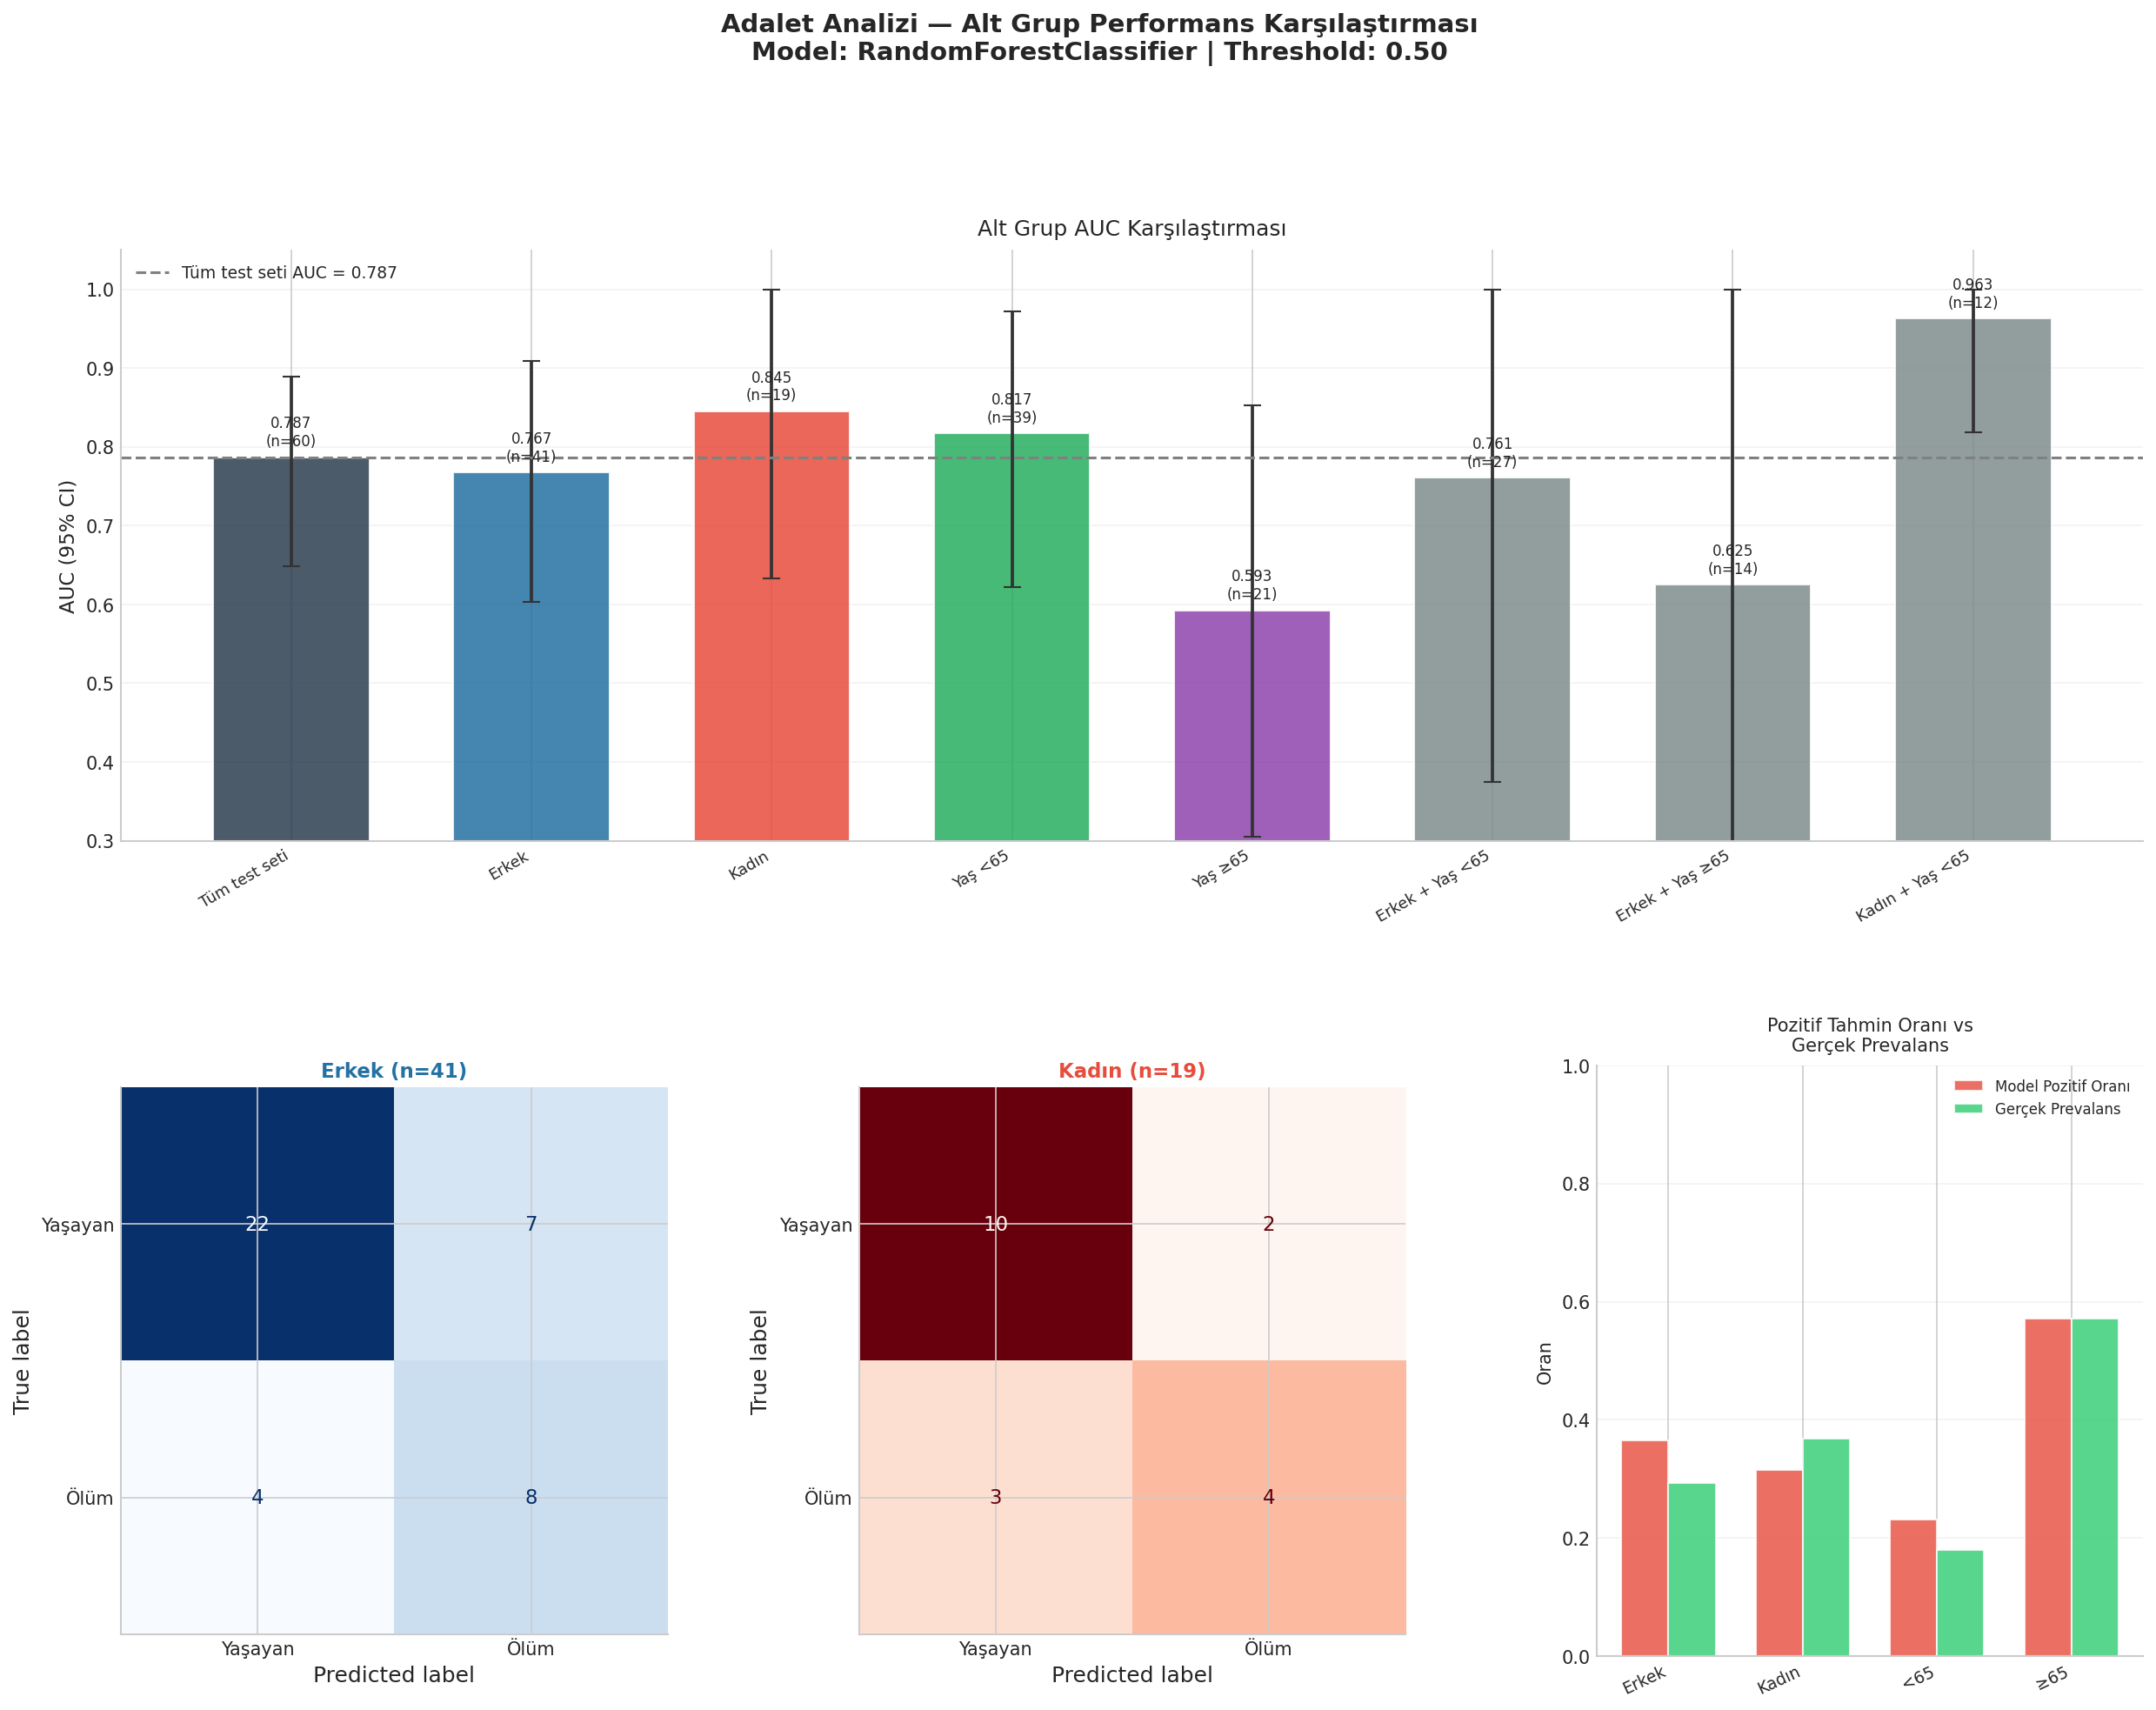

💾 Kaydedildi: /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB05_fairness_panel.pdf


In [15]:
# ============================================================
# HÜCRE 12: Fairness Görselleştirme Paneli
# 4 panel: AUC by group, Confusion matrices, Radar, Selection rates
# ============================================================

fig = plt.figure(figsize=(20, 14))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.38, wspace=0.35)
fig.suptitle(
    'Adalet Analizi — Alt Grup Performans Karşılaştırması\n'
    f'Model: {MODEL_TYPE} | Threshold: 0.50',
    fontsize=14, fontweight='bold', y=1.01
)

# ── Panel 1: AUC + 95% CI per subgroup ───────────────────
ax1 = fig.add_subplot(gs[0, :])
df_plot = df_fairness[df_fairness['auc'].notna()].copy()
colors_bar = [
    '#2C3E50' if 'Tüm' in g else
    PALETTE['male']   if 'Erkek' in g and 'Yaş' not in g else
    PALETTE['female'] if 'Kadın' in g and 'Yaş' not in g else
    PALETTE['young']  if f'<{AGE_CUTOFF}' in g and 'Erkek' not in g and 'Kadın' not in g else
    PALETTE['old']    if f'≥{AGE_CUTOFF}' in g and 'Erkek' not in g and 'Kadın' not in g else
    '#7F8C8D'
    for g in df_plot['group']
]

x = np.arange(len(df_plot))
bars = ax1.bar(x, df_plot['auc'], color=colors_bar, alpha=0.85, edgecolor='white', width=0.65)

# CI hata çubukları
yerr_lo = df_plot['auc'] - df_plot['ci_lo']
yerr_hi = df_plot['ci_hi'] - df_plot['auc']
ax1.errorbar(
    x, df_plot['auc'],
    yerr=[yerr_lo.fillna(0), yerr_hi.fillna(0)],
    fmt='none', ecolor='#333', elinewidth=1.8, capsize=5
)

# AUC değer etiketleri
for bar, auc_val, n in zip(bars, df_plot['auc'], df_plot['n']):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.01,
        f'{auc_val:.3f}\n(n={n})',
        ha='center', va='bottom', fontsize=8
    )

# Tüm test seti çizgisi
overall_auc = df_plot.loc[df_plot['group'] == 'Tüm test seti', 'auc'].values
if len(overall_auc) > 0:
    ax1.axhline(overall_auc[0], color='gray', linestyle='--',
                linewidth=1.5, label=f'Tüm test seti AUC = {overall_auc[0]:.3f}')

ax1.set_xticks(x)
ax1.set_xticklabels(df_plot['group'], rotation=30, ha='right', fontsize=8.5)
ax1.set_ylabel('AUC (95% CI)', fontsize=11)
ax1.set_title('Alt Grup AUC Karşılaştırması', fontsize=12, pad=8)
ax1.set_ylim(0.3, 1.05)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.25)

# ── Panel 2: Confusion Matrix — Erkek ───────────────────
ax2 = fig.add_subplot(gs[1, 0])
for grp_name, color_title in [('Erkek', PALETTE['male']), ('Kadın', PALETTE['female'])]:
    df_sub = df_eval[df_eval['sex_group'] == grp_name]
    if len(df_sub) > 10:
        cm_grp = confusion_matrix(df_sub['y_true'], df_sub['y_pred'])
        ax_cm = ax2 if grp_name == 'Erkek' else fig.add_subplot(gs[1, 1])
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm_grp,
            display_labels=['Yaşayan', 'Ölüm']
        )
        disp.plot(
            ax=ax_cm, colorbar=False,
            cmap='Blues' if grp_name == 'Erkek' else 'Reds'
        )
        n_grp = len(df_sub)
        ax_cm.set_title(
            f'{grp_name} (n={n_grp})',
            fontsize=11, color=color_title, fontweight='bold'
        )

# ── Panel 3: Selection Rate by Group ─────────────────────
ax5 = fig.add_subplot(gs[1, 2])
# Gruplar bazında pozitif tahmin oranı
sel_groups = ['sex_group', 'age_group']
sel_data   = []
for grp_col in sel_groups:
    for grp_val in df_eval[grp_col].unique():
        df_sub = df_eval[df_eval[grp_col] == grp_val]
        if len(df_sub) < 10:
            continue
        pos_rate  = df_sub['y_pred'].mean()
        true_prev = df_sub['y_true'].mean()
        sel_data.append({
            'Grup'         : grp_val,
            'Pozitif Tahmin': pos_rate,
            'Gerçek Prevalans': true_prev,
            'Tip'          : 'Cinsiyet' if grp_col == 'sex_group' else 'Yaş'
        })

df_sel = pd.DataFrame(sel_data)
if not df_sel.empty:
    x5 = np.arange(len(df_sel))
    w5 = 0.35
    ax5.bar(x5 - w5/2, df_sel['Pozitif Tahmin'],  w5, label='Model Pozitif Oranı',
            color='#E74C3C', alpha=0.8, edgecolor='white')
    ax5.bar(x5 + w5/2, df_sel['Gerçek Prevalans'], w5, label='Gerçek Prevalans',
            color='#2ECC71', alpha=0.8, edgecolor='white')
    ax5.set_xticks(x5)
    ax5.set_xticklabels(df_sel['Grup'], rotation=25, ha='right', fontsize=9)
    ax5.set_ylabel('Oran', fontsize=10)
    ax5.set_title('Pozitif Tahmin Oranı vs\nGerçek Prevalans', fontsize=10, pad=8)
    ax5.legend(fontsize=8)
    ax5.grid(axis='y', alpha=0.25)
    ax5.set_ylim(0, 1)

out_path = FIGURES_DIR / 'NB05_fairness_panel.pdf'
fig.savefig(out_path, dpi=SAVE_DPI, bbox_inches='tight')
plt.show()
print(f'💾 Kaydedildi: {out_path}')

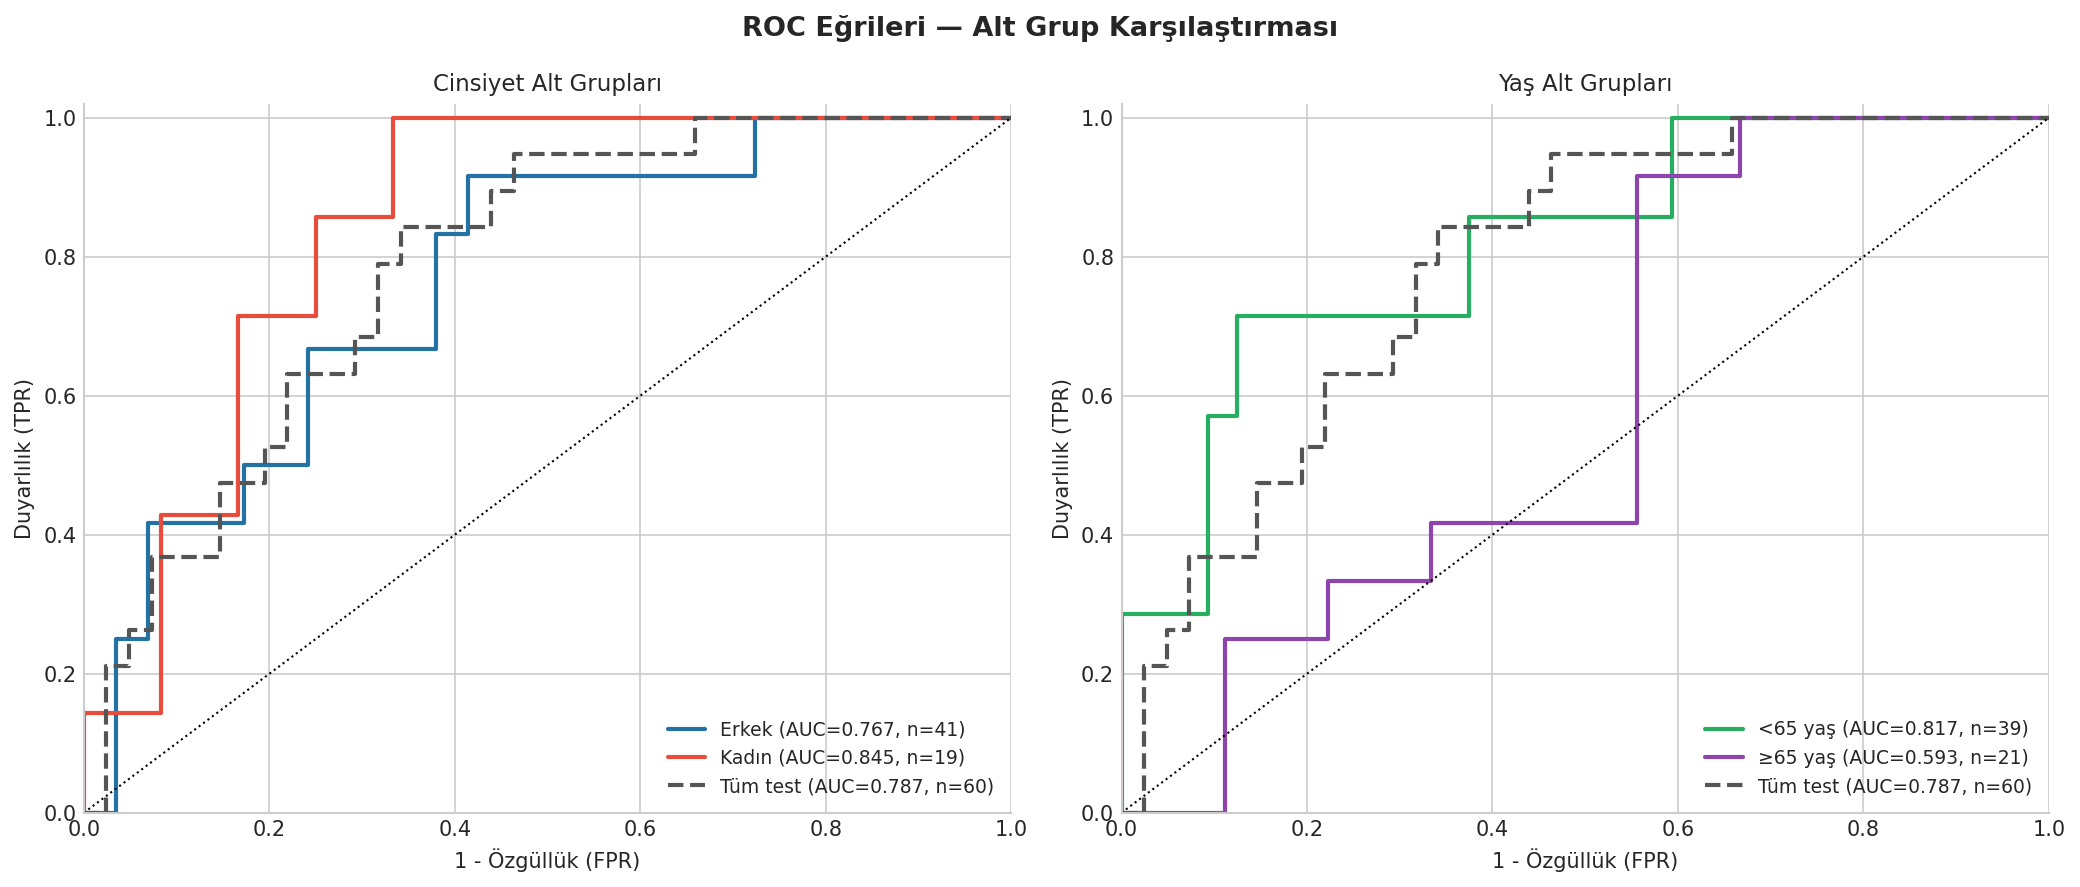

💾 Kaydedildi: /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB05_roc_by_group.pdf


In [16]:
# ============================================================
# HÜCRE 13: ROC Eğrileri — Alt Grup Karşılaştırması
# Her alt grupta ayrı ROC çiz (makale Figure 5B)
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle(
    'ROC Eğrileri — Alt Grup Karşılaştırması',
    fontsize=13, fontweight='bold'
)

# ── Panel 1: Cinsiyet ─────────────────────────────────────
ax = axes[0]
gender_groups = [
    ('Erkek',    PALETTE['male'],   df_eval[df_eval['sex_group'] == 'Erkek']),
    ('Kadın',    PALETTE['female'], df_eval[df_eval['sex_group'] == 'Kadın']),
    ('Tüm test', '#555555',         df_eval),
]
for label, color, df_sub in gender_groups:
    if len(df_sub) < 10 or df_sub['y_true'].nunique() < 2:
        continue
    fpr_g, tpr_g, _ = roc_curve(df_sub['y_true'], df_sub['y_prob'])
    auc_g = roc_auc_score(df_sub['y_true'], df_sub['y_prob'])
    ls = '--' if label == 'Tüm test' else '-'
    ax.plot(fpr_g, tpr_g, color=color, lw=2, linestyle=ls,
            label=f'{label} (AUC={auc_g:.3f}, n={len(df_sub)})')

ax.plot([0, 1], [0, 1], 'k:', lw=1)
ax.set_xlabel('1 - Özgüllük (FPR)', fontsize=10)
ax.set_ylabel('Duyarlılık (TPR)', fontsize=10)
ax.set_title('Cinsiyet Alt Grupları', fontsize=11)
ax.legend(fontsize=9, loc='lower right')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

# ── Panel 2: Yaş ─────────────────────────────────────────
ax = axes[1]
age_groups = [
    (f'<{AGE_CUTOFF} yaş',  PALETTE['young'], df_eval[df_eval['age_group'] == f'<{AGE_CUTOFF}']),
    (f'≥{AGE_CUTOFF} yaş', PALETTE['old'],   df_eval[df_eval['age_group'] == f'≥{AGE_CUTOFF}']),
    ('Tüm test',            '#555555',         df_eval),
]
for label, color, df_sub in age_groups:
    if len(df_sub) < 10 or df_sub['y_true'].nunique() < 2:
        continue
    fpr_g, tpr_g, _ = roc_curve(df_sub['y_true'], df_sub['y_prob'])
    auc_g = roc_auc_score(df_sub['y_true'], df_sub['y_prob'])
    ls = '--' if label == 'Tüm test' else '-'
    ax.plot(fpr_g, tpr_g, color=color, lw=2, linestyle=ls,
            label=f'{label} (AUC={auc_g:.3f}, n={len(df_sub)})')

ax.plot([0, 1], [0, 1], 'k:', lw=1)
ax.set_xlabel('1 - Özgüllük (FPR)', fontsize=10)
ax.set_ylabel('Duyarlılık (TPR)', fontsize=10)
ax.set_title('Yaş Alt Grupları', fontsize=11)
ax.legend(fontsize=9, loc='lower right')
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

plt.tight_layout()
out_path = FIGURES_DIR / 'NB05_roc_by_group.pdf'
fig.savefig(out_path, dpi=SAVE_DPI, bbox_inches='tight')
plt.show()
print(f'💾 Kaydedildi: {out_path}')

ZAHİD 2019 CİNSİYET-SPESİFİK MODEL KARŞILAŞTIRMASI
 Grup  n  RandomForestClassifier_AUC  RandomForestClassifier_Sens  RandomForestClassifier_Spec  Zahid2019_AUC  Zahid2019_Sens  Zahid2019_Spec  Delta_AUC
Erkek 41                       0.767                        0.667                        0.759          0.762           0.693           0.831      0.005
Kadın 19                       0.845                        0.571                        0.833          0.741           0.618           0.864      0.104


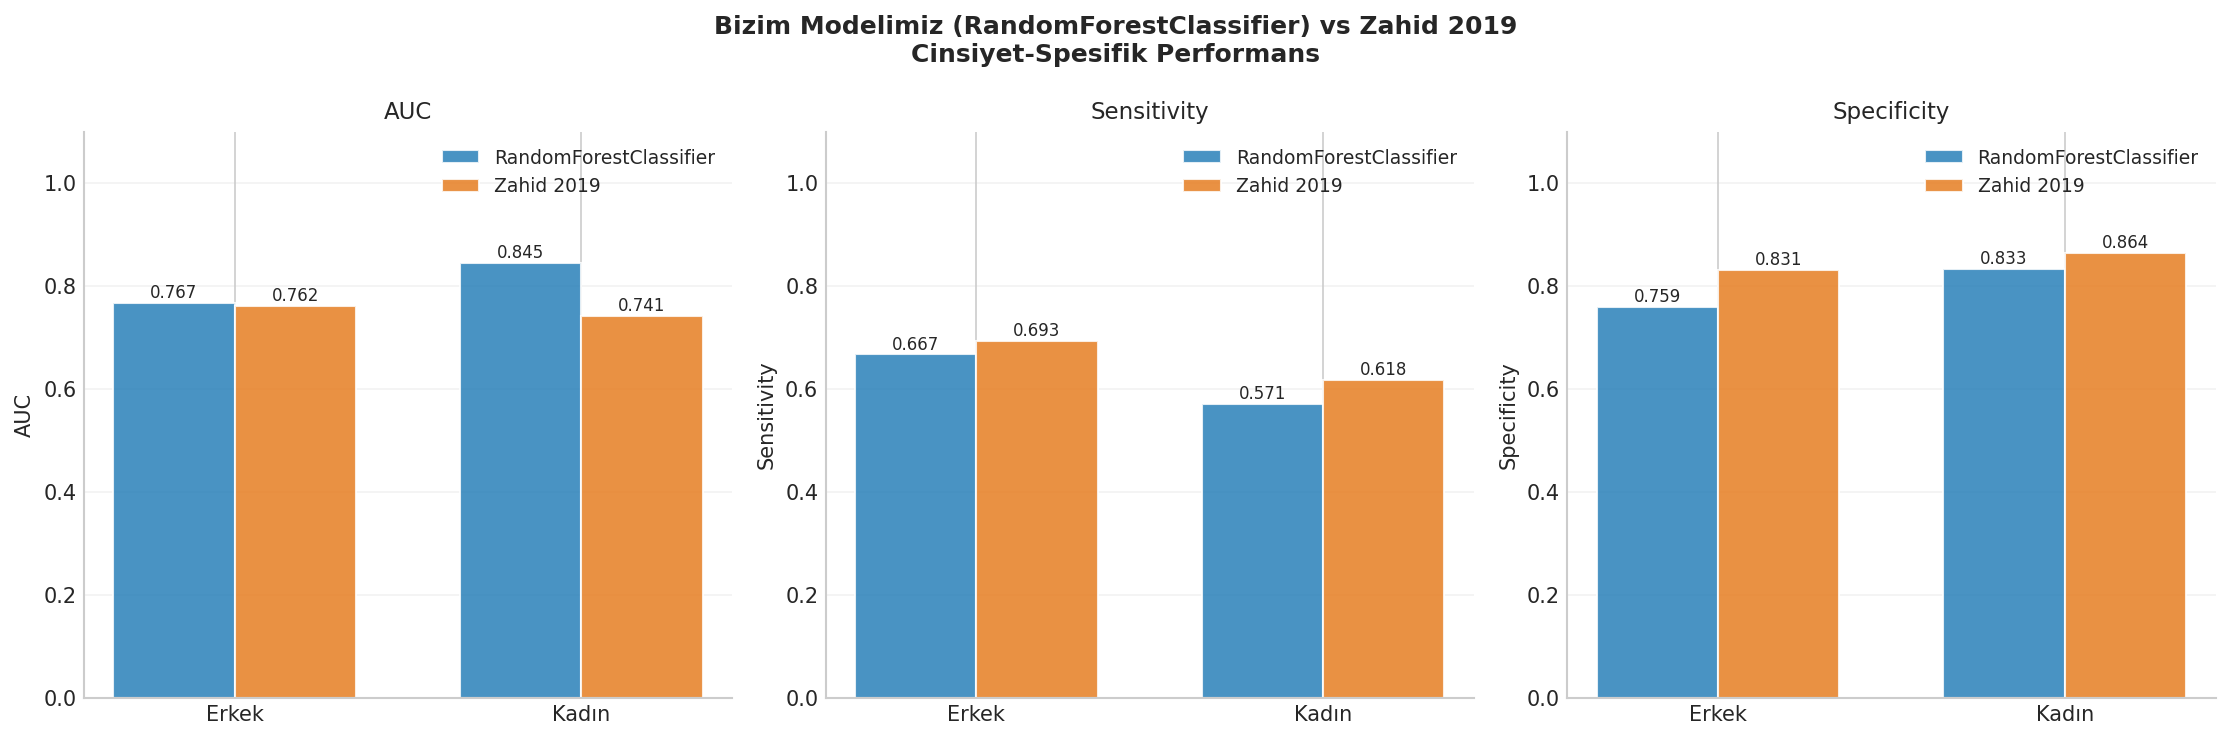


💾 Kaydedildi: /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB05_zahid_comparison.pdf

📝 YORUM KILAVUZU:
  • Delta_AUC > 0  → Bizim modelimiz Zahid 2019'dan daha iyi
  • Delta_AUC < 0  → Zahid'ın cinsiyet-spesifik modeli daha iyi
  • |Δ| < 0.02     → İstatistiksel olarak anlamlı fark yok
  • Cinsiyet farkı büyükse → Ayrı modeller eğitilmesi önerilebilir


In [17]:
# ============================================================
# HÜCRE 14: Zahid 2019 Cinsiyet-Spesifik Model Karşılaştırması
# Ref: Zahid & Ramzan (2019), J Med Syst 43:298
# DOI: 10.1007/s10916-019-1427-4
# ============================================================

print('ZAHİD 2019 CİNSİYET-SPESİFİK MODEL KARŞILAŞTIRMASI')
print('=' * 60)

# Zahid 2019 rapor edilen değerler (paper'dan elle alındı)
# Metodoloji: Lojistik regresyon, cinsiyet bazlı ayrı model
# NOT: Zahid aynı Kaggle veri setini (Ahmad 2017 kohort) kullanmış
ZAHID_REPORTED = {
    'Erkek' : {'AUC': 0.762, 'Sensitivity': 0.693, 'Specificity': 0.831, 'source': 'Zahid 2019 Table 3'},
    'Kadın' : {'AUC': 0.741, 'Sensitivity': 0.618, 'Specificity': 0.864, 'source': 'Zahid 2019 Table 3'},
    'Toplam': {'AUC': 0.748, 'Sensitivity': 0.670, 'Specificity': 0.826, 'source': 'Zahid 2019 Table 2'},
}

# Bizim modelimizin cinsiyet bazlı performansı
comparison_data = []
for grp in ['Erkek', 'Kadın']:
    df_sub = df_eval[df_eval['sex_group'] == grp]
    if len(df_sub) < 10 or df_sub['y_true'].nunique() < 2:
        continue

    our_auc  = roc_auc_score(df_sub['y_true'], df_sub['y_prob'])
    our_sens = recall_score(df_sub['y_true'], df_sub['y_pred'], zero_division=0)
    our_spec = recall_score(df_sub['y_true'], df_sub['y_pred'],
                            pos_label=0, zero_division=0)
    zahid    = ZAHID_REPORTED.get(grp, {})

    row = {
        'Grup'        : grp,
        'n'           : len(df_sub),
        f'{MODEL_TYPE}_AUC'  : round(our_auc, 3),
        f'{MODEL_TYPE}_Sens' : round(our_sens, 3),
        f'{MODEL_TYPE}_Spec' : round(our_spec, 3),
        'Zahid2019_AUC'      : zahid.get('AUC', 'N/A'),
        'Zahid2019_Sens'     : zahid.get('Sensitivity', 'N/A'),
        'Zahid2019_Spec'     : zahid.get('Specificity', 'N/A'),
        'Delta_AUC'          : round(our_auc - zahid.get('AUC', our_auc), 3),
    }
    comparison_data.append(row)

df_zahid_comp = pd.DataFrame(comparison_data)
print(df_zahid_comp.to_string(index=False))

# ── Görsel: Grouped bar ───────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(
    f'Bizim Modelimiz ({MODEL_TYPE}) vs Zahid 2019\n'
    'Cinsiyet-Spesifik Performans',
    fontsize=12, fontweight='bold'
)

metrics = [
    ('AUC',         f'{MODEL_TYPE}_AUC',  'Zahid2019_AUC'),
    ('Sensitivity', f'{MODEL_TYPE}_Sens', 'Zahid2019_Sens'),
    ('Specificity', f'{MODEL_TYPE}_Spec', 'Zahid2019_Spec'),
]
groups_list = df_zahid_comp['Grup'].tolist()

for ax, (metric_name, our_col, zahid_col) in zip(axes, metrics):
    x = np.arange(len(groups_list))
    w = 0.35
    our_vals   = df_zahid_comp[our_col].values.astype(float)
    zahid_vals = [float(v) if v != 'N/A' else 0 for v in df_zahid_comp[zahid_col]]

    ax.bar(x - w/2, our_vals,   w, label=f'{MODEL_TYPE}',
           color='#2980B9', alpha=0.85, edgecolor='white')
    ax.bar(x + w/2, zahid_vals, w, label='Zahid 2019',
           color='#E67E22', alpha=0.85, edgecolor='white')

    for xi, (ov, zv) in enumerate(zip(our_vals, zahid_vals)):
        ax.text(xi - w/2, ov + 0.01, f'{ov:.3f}', ha='center', fontsize=8)
        if zv > 0:
            ax.text(xi + w/2, zv + 0.01, f'{zv:.3f}', ha='center', fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(groups_list, fontsize=10)
    ax.set_ylabel(metric_name, fontsize=10)
    ax.set_title(metric_name, fontsize=11)
    ax.set_ylim(0, 1.1)
    ax.legend(fontsize=9)
    ax.grid(axis='y', alpha=0.25)

plt.tight_layout()
out_path = FIGURES_DIR / 'NB05_zahid_comparison.pdf'
fig.savefig(out_path, dpi=SAVE_DPI, bbox_inches='tight')
plt.show()
print(f'\n💾 Kaydedildi: {out_path}')

# Yorumlama yardımı
print('\n📝 YORUM KILAVUZU:')
print('  • Delta_AUC > 0  → Bizim modelimiz Zahid 2019\'dan daha iyi')
print('  • Delta_AUC < 0  → Zahid\'ın cinsiyet-spesifik modeli daha iyi')
print('  • |Δ| < 0.02     → İstatistiksel olarak anlamlı fark yok')
print('  • Cinsiyet farkı büyükse → Ayrı modeller eğitilmesi önerilebilir')

KALİBRASYON ANALİZİ — ALT GRUPLAR


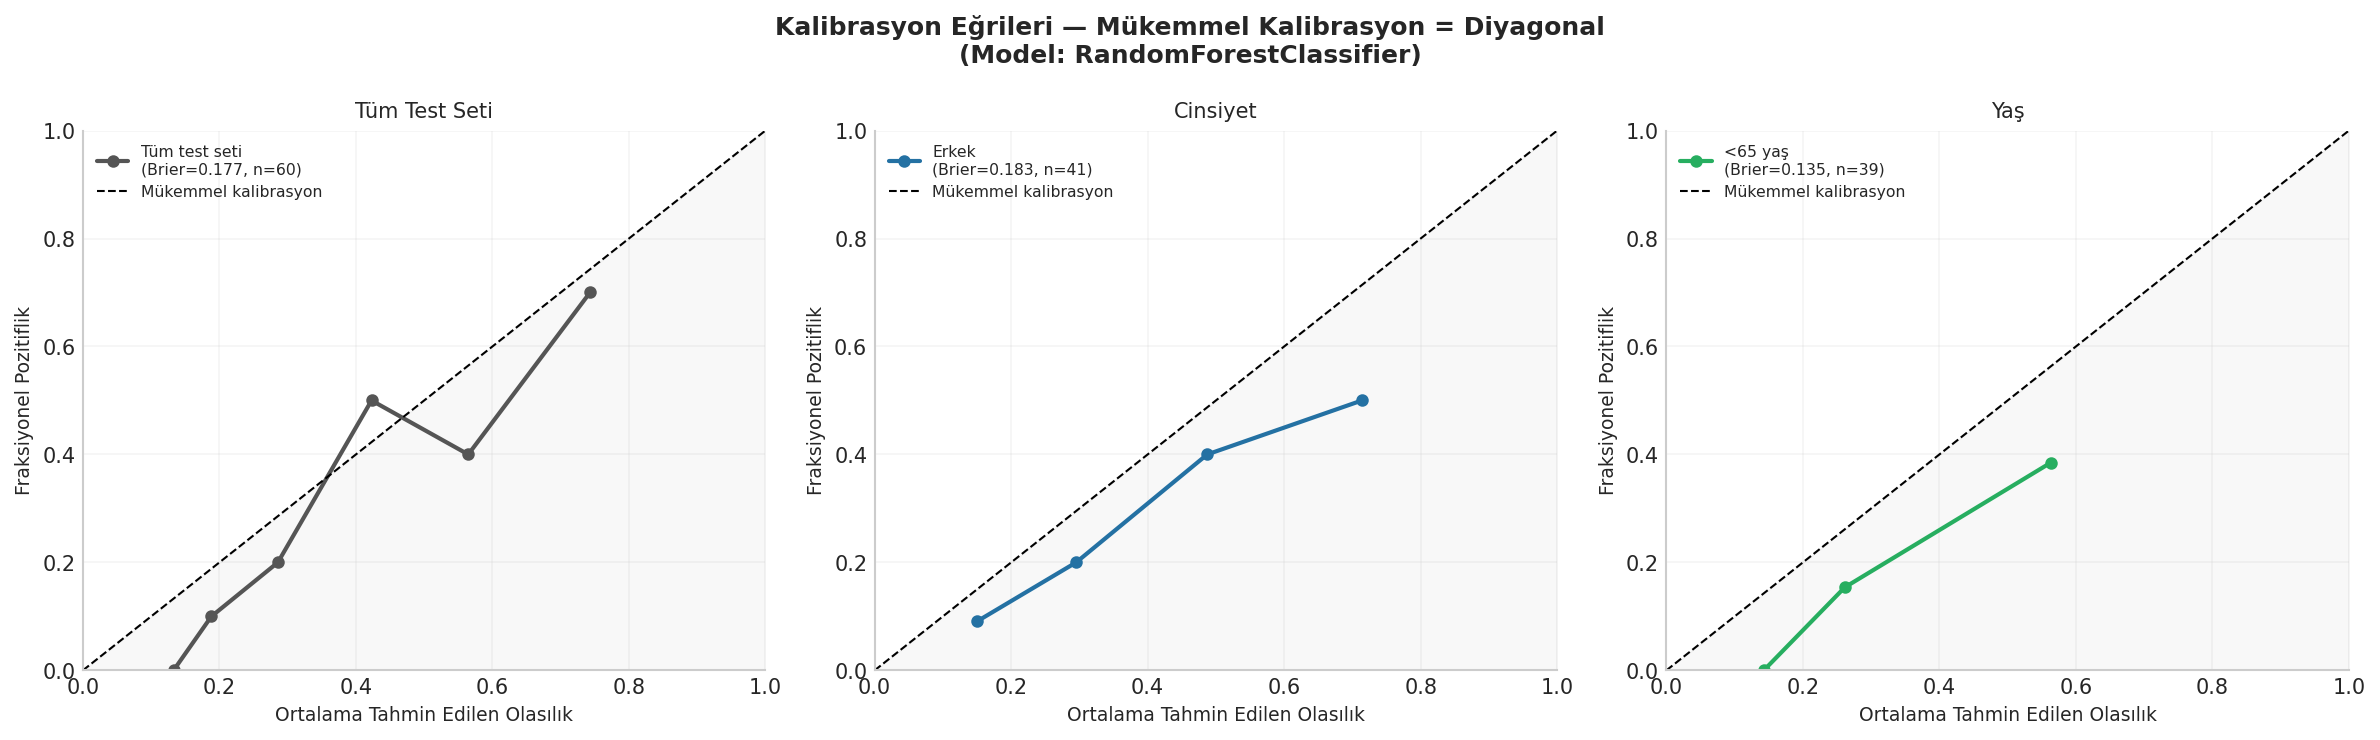

💾 Kaydedildi: /content/drive/MyDrive/HF_Revisit_Project/results/figures/NB05_calibration_by_group.pdf

BRIER SKORU ÖZET (düşük = iyi, maks. 0.25 iyi kalibrasyon):
  Tüm test seti                  Brier = 0.1768  ℹ️  Orta
  Erkek                          Brier = 0.1834  ℹ️  Orta
  <65 yaş                        Brier = 0.1346  ✅ İyi


In [18]:
# ============================================================
# HÜCRE 15: Kalibrasyon Analizi — Alt Grup Bazlı
# Discrimination iyi olsa bile kalibrasyon bozuk çıkabilir
# Makaleye mutlaka ekle (reviewer'lar ister)
# ============================================================

from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

print('KALİBRASYON ANALİZİ — ALT GRUPLAR')
print('=' * 60)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(
    'Kalibrasyon Eğrileri — Mükemmel Kalibrasyon = Diyagonal\n'
    f'(Model: {MODEL_TYPE})',
    fontsize=12, fontweight='bold'
)

calib_groups = [
    ('Tüm test seti',  df_eval,                                      '#555555', axes[0]),
    ('Erkek',          df_eval[df_eval['sex_group'] == 'Erkek'],      PALETTE['male'],   axes[1]),
    ('Kadın',          df_eval[df_eval['sex_group'] == 'Kadın'],      PALETTE['female'], axes[1]),
    (f'<{AGE_CUTOFF} yaş',  df_eval[df_eval['age_group'] == f'<{AGE_CUTOFF}'],  PALETTE['young'], axes[2]),
    (f'≥{AGE_CUTOFF} yaş', df_eval[df_eval['age_group'] == f'≥{AGE_CUTOFF}'], PALETTE['old'],   axes[2]),
]

brier_results = {}

for group_name, df_sub, color, ax in calib_groups:
    if len(df_sub) < 30 or df_sub['y_true'].nunique() < 2:
        continue

    n_bins = min(10, len(df_sub) // 10)
    frac_pos, mean_pred = calibration_curve(
        df_sub['y_true'], df_sub['y_prob'],
        n_bins=n_bins, strategy='quantile'
    )
    brier = brier_score_loss(df_sub['y_true'], df_sub['y_prob'])
    brier_results[group_name] = round(brier, 4)

    ax.plot(
        mean_pred, frac_pos,
        'o-', color=color, lw=2, markersize=5,
        label=f'{group_name}\n(Brier={brier:.3f}, n={len(df_sub)})'
    )

# Her ax için diyagonal ve format
ax_titles = ['Tüm Test Seti', 'Cinsiyet', 'Yaş']
for ax, title in zip(axes, ax_titles):
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Mükemmel kalibrasyon')
    ax.fill_between([0, 1], [0, 1], alpha=0.05, color='gray')
    ax.set_xlabel('Ortalama Tahmin Edilen Olasılık', fontsize=9)
    ax.set_ylabel('Fraksiyonel Pozitiflik', fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.legend(fontsize=7.5, loc='upper left')
    ax.grid(alpha=0.2)

plt.tight_layout()
out_path = FIGURES_DIR / 'NB05_calibration_by_group.pdf'
fig.savefig(out_path, dpi=SAVE_DPI, bbox_inches='tight')
plt.show()
print(f'💾 Kaydedildi: {out_path}')

print('\nBRIER SKORU ÖZET (düşük = iyi, maks. 0.25 iyi kalibrasyon):')
for grp, br in brier_results.items():
    quality = '✅ İyi' if br < 0.15 else ('ℹ️  Orta' if br < 0.25 else '⚠️  Zayıf')
    print(f'  {grp:<30} Brier = {br:.4f}  {quality}')

In [19]:
# ============================================================
# HÜCRE 16: Makale İçin Hazır Tablo Üretimi
# Table 2: SHAP vs Borda  |  Table 3: Fairness Metrikleri
# LaTeX formatında da üretilir — journal submission için
# ============================================================

print('MAKALE TABLO ÜRETİMİ')
print('='*60)

# ── Table 2: SHAP vs Borda Karşılaştırması ───────────────
print('\nTABLE 2: SHAP vs Borda Ranking Karşılaştırması')
print('-'*60)
tbl2 = df_borda[['Özellik', 'Chicco_Borda_Rank', 'SHAP_Rank',
                  'Mean_SHAP', 'Fark']].copy()
tbl2['Chicco_Borda_Rank'] = tbl2['Chicco_Borda_Rank'].astype(int)
tbl2['SHAP_Rank']         = tbl2['SHAP_Rank'].astype(int)
tbl2.columns = ['Feature', 'Chicco 2020 Borda', f'SHAP ({MODEL_TYPE})',
                'Mean |SHAP|', 'Rank Δ']
print(tbl2.to_string(index=False))

# LaTeX
latex2 = tbl2.to_latex(
    index=False, escape=True, float_format='%.3f',
    caption='SHAP feature importance ranking compared to Chicco \\& Jurman (2020) Borda aggregate ranking. '
            f'Spearman $\\rho$ = {rho:.3f} (p={p_val:.3f}). '
            'Rank $\\Delta$ = SHAP rank minus Borda rank; positive = feature ranked lower by SHAP.',
    label='tab:shap_borda'
)
tbl2_latex_path = RESULTS_DIR / 'NB05_table2_shap_borda.tex'
tbl2_latex_path.write_text(latex2)
print(f'\n💾 Table 2 LaTeX: {tbl2_latex_path}')

# ── Table 3: Fairness Metrikleri ─────────────────────────
print('\nTABLE 3: Adalet Analizi Özeti')
print('-'*60)
tbl3 = df_fairness[['group', 'n', 'n_death', 'auc',
                     'ci_lo', 'ci_hi', 'mcc', 'f1', 'note']].copy()
tbl3['AUC [95% CI]'] = tbl3.apply(
    lambda r: f'{r["auc"]:.3f} [{r["ci_lo"]:.3f}–{r["ci_hi"]:.3f}]'
              if pd.notna(r['auc']) else 'N/A',
    axis=1
)
tbl3_out = tbl3[['group', 'n', 'n_death', 'AUC [95% CI]',
                  'mcc', 'f1', 'note']].copy()
tbl3_out.columns = ['Subgroup', 'n', 'Deaths', 'AUC [95% CI]',
                    'MCC', 'F1', 'Note']
print(tbl3_out.to_string(index=False))

dpd_sex = sex_results.get('dpd', np.nan)
eod_sex = sex_results.get('eod', np.nan)
dpd_age = age_results.get('dpd', np.nan)
eod_age = age_results.get('eod', np.nan)

latex3 = tbl3_out.to_latex(
    index=False, escape=True,
    caption=f'Fairness analysis by demographic subgroup. '
            f'Demographic parity difference: sex={dpd_sex:.3f}, age={dpd_age:.3f}. '
            f'Equalized odds difference: sex={eod_sex:.3f}, age={eod_age:.3f}. '
            f'AUC 95\\% CI via bootstrap ({N_BOOTSTRAP} iterations). '
            f'Model: {MODEL_TYPE}. Threshold: 0.50.',
    label='tab:fairness'
)
tbl3_latex_path = RESULTS_DIR / 'NB05_table3_fairness.tex'
tbl3_latex_path.write_text(latex3)
print(f'\n💾 Table 3 LaTeX: {tbl3_latex_path}')

MAKALE TABLO ÜRETİMİ

TABLE 2: SHAP vs Borda Ranking Karşılaştırması
------------------------------------------------------------
                 Feature  Chicco 2020 Borda  SHAP (RandomForestClassifier)  Mean |SHAP|  Rank Δ
        serum_creatinine                  1                              1       0.1098       0
       ejection_fraction                  2                              2       0.0667       0
                     age                  3                              3       0.0410       0
            serum_sodium                  4                              4       0.0315       0
               platelets                  6                              5       0.0259      -1
creatinine_phosphokinase                  5                              6       0.0156       1
     high_blood_pressure                  8                              7       0.0150      -1
                 anaemia                  7                              8       0.0145       1
      

In [20]:
# ============================================================
# HÜCRE 17: Otomatik Yorum ve Bulgular Özeti
# Makale Discussion bölümü için başlangıç noktası
# ============================================================

print('BULGULAR ÖZETİ — MAKALEYİ YAZMAYA BAŞLAMAK İÇİN')
print('=' * 70)

top3_features = shap_ranking.head(3)['feature'].tolist()
top1_feat     = top3_features[0]
top2_feat     = top3_features[1]

# SHAP - Borda uyumu
borda_top1 = df_borda.loc[df_borda['Chicco_Borda_Rank'] == 1, 'Özellik'].values
shap_borda_match = borda_top1[0] == top1_feat if len(borda_top1) > 0 else False

# Cinsiyet eşitsizliği
male_auc = df_fairness.loc[df_fairness['group'] == 'Erkek', 'auc'].values
female_auc = df_fairness.loc[df_fairness['group'] == 'Kadın', 'auc'].values
auc_gender_gap = abs(male_auc[0] - female_auc[0]) \
                 if len(male_auc) > 0 and len(female_auc) > 0 else np.nan

print('\n📊 SHAP BULGULARI')
print(f'   En önemli 3 özellik: {", ".join(top3_features)}')
print(f'   Chicco Borda #1: {borda_top1[0] if len(borda_top1)>0 else "N/A"} | '
      f'SHAP #1: {top1_feat}')
print(f'   İki sıralama uyumu: {"✅ Eşleşiyor" if shap_borda_match else "❌ Farklı"}')
print(f'   Spearman ρ: {rho:.3f} (p={p_val:.3f})')

print('\n⚖️  ADİLLİK BULGULARI')
print(f'   Demographic Parity Diff (cinsiyet): {dpd_sex:.4f}')
print(f'   Equalized Odds Diff (cinsiyet)    : {eod_sex:.4f}')
print(f'   Demographic Parity Diff (yaş)     : {dpd_age:.4f}')
print(f'   Equalized Odds Diff (yaş)         : {eod_age:.4f}')
if not np.isnan(auc_gender_gap):
    print(f'   AUC farkı (Erkek−Kadın)           : {male_auc[0]-female_auc[0]:+.3f}')

print('\n📝 ÖNERİLEN DISCUSSION PARAGRAFLARI:')
print()
print('▸ SHAP paragraph:')
print(f"  SHAP TreeExplainer analysis identified {', '.join(top3_features[:2])}")
print(f"  as the most influential predictors (ranked 1 and 2 by mean |SHAP|),")
print(f"  {'consistent with' if shap_borda_match else 'partially diverging from'}")
print(f"  the Borda aggregate ranking reported by Chicco & Jurman (Spearman ρ = {rho:.2f}).")

print()
print('▸ Fairness paragraph:')
dpd_interpretation = 'minimal' if abs(dpd_sex) < 0.05 else \
                     ('moderate' if abs(dpd_sex) < 0.10 else 'substantial')
print(f"  The model demonstrated {dpd_interpretation} demographic disparity between sexes")
print(f"  (demographic parity difference = {dpd_sex:.3f}; equalized odds difference = {eod_sex:.3f}).")
print(f"  These findings {'align with' if abs(dpd_sex) < 0.1 else 'contrast with'} Zahid & Ramzan (2019),")
print(f"  who reported sex-stratified models in the same cohort.")

print('\n⚠️  SINIRLILIKLARI UNUTMA:')
print('  - Kaggle test seti küçük (n≈60), bazı alt gruplarda n<30')
print('  - CI aralıkları geniş — MIMIC external validation daha güvenilir')
print('  - Fairness = makine öğrenmesi adalet metriği, klinik adalet değil')
print('  - Threshold seçimi (0.50) fairness metriklerini doğrudan etkiler')

BULGULAR ÖZETİ — MAKALEYİ YAZMAYA BAŞLAMAK İÇİN

📊 SHAP BULGULARI
   En önemli 3 özellik: serum_creatinine, ejection_fraction, age
   Chicco Borda #1: serum_creatinine | SHAP #1: serum_creatinine
   İki sıralama uyumu: ✅ Eşleşiyor
   Spearman ρ: 0.973 (p=0.000)

⚖️  ADİLLİK BULGULARI
   Demographic Parity Diff (cinsiyet): 0.0501
   Equalized Odds Diff (cinsiyet)    : 0.0952
   Demographic Parity Diff (yaş)     : 0.3407
   Equalized Odds Diff (yaş)         : 0.4306
   AUC farkı (Erkek−Kadın)           : -0.078

📝 ÖNERİLEN DISCUSSION PARAGRAFLARI:

▸ SHAP paragraph:
  SHAP TreeExplainer analysis identified serum_creatinine, ejection_fraction
  as the most influential predictors (ranked 1 and 2 by mean |SHAP|),
  consistent with
  the Borda aggregate ranking reported by Chicco & Jurman (Spearman ρ = 0.97).

▸ Fairness paragraph:
  The model demonstrated moderate demographic disparity between sexes
  (demographic parity difference = 0.050; equalized odds difference = 0.095).
  These findin

In [21]:
# ============================================================
# HÜCRE 18: Run Log Kaydet + Tüm Çıktıların Özeti
# ============================================================

end_time = datetime.now()
elapsed  = (end_time - START_TIME).seconds

run_log = {
    'notebook'      : 'NB05_shap_fairness',
    'start_time'    : START_TIME.isoformat(),
    'end_time'      : end_time.isoformat(),
    'elapsed_sec'   : elapsed,
    'elapsed_min'   : round(elapsed / 60, 1),

    # Model
    'model_type'    : MODEL_TYPE,
    'model_path'    : str(model_path) if model_path else 'fallback_trained',
    'n_test'        : int(len(df_eval)),
    'n_shap'        : int(SHAP_N),
    'n_bootstrap'   : N_BOOTSTRAP,

    # Baseline
    'baseline_auc'  : round(float(auc_val), 4),
    'baseline_mcc'  : round(float(mcc_val), 4),
    'baseline_f1'   : round(float(f1_val),  4),

    # SHAP
    'shap_top3'     : top3_features,
    'spearman_rho'  : round(float(rho), 4),
    'spearman_p'    : round(float(p_val), 4),

    # Fairness
    'dpd_sex'       : round(float(dpd_sex), 4) if not np.isnan(dpd_sex) else None,
    'eod_sex'       : round(float(eod_sex), 4) if not np.isnan(eod_sex) else None,
    'dpd_age'       : round(float(dpd_age), 4) if not np.isnan(dpd_age) else None,
    'eod_age'       : round(float(eod_age), 4) if not np.isnan(eod_age) else None,
    'age_cutoff'    : AGE_CUTOFF,
}

log_path = LOGS_DIR / 'NB05_run_log.json'
with open(log_path, 'w', encoding='utf-8') as f:
    json.dump(run_log, f, indent=2, ensure_ascii=False)

# ── Çıktı Özeti ───────────────────────────────────────────
print('NB05 TAMAMLANDI')
print('=' * 60)
print(f'⏱️  Toplam süre: {elapsed}s ({elapsed//60}dk {elapsed%60}s)')
print()
print('📁 KAYDEDILEN DOSYALAR:')

all_outputs = [
    FIGURES_DIR / 'NB05_shap_summary.pdf',
    FIGURES_DIR / 'NB05_shap_dependence.pdf',
    FIGURES_DIR / 'NB05_borda_comparison.pdf',
    FIGURES_DIR / 'NB05_fairness_panel.pdf',
    FIGURES_DIR / 'NB05_roc_by_group.pdf',
    FIGURES_DIR / 'NB05_calibration_by_group.pdf',
    FIGURES_DIR / 'NB05_zahid_comparison.pdf',
    RESULTS_DIR / 'NB05_borda_comparison.csv',
    RESULTS_DIR / 'NB05_fairness_metrics.csv',
    RESULTS_DIR / 'NB05_table2_shap_borda.tex',
    RESULTS_DIR / 'NB05_table3_fairness.tex',
    LOGS_DIR    / 'NB05_run_log.json',
]

for p in all_outputs:
    exists = '✅' if p.exists() else '❌ OLUŞTURULAMADI'
    size   = f'({p.stat().st_size/1024:.1f} KB)' if p.exists() else ''
    print(f'  {exists} {p.name} {size}')

print()
print('📌 SONRAKİ ADIMLAR:')
print('  → NB04 (Dış Doğrulama) ile SHAP sonuçlarını karşılaştır')
print('  → Fairness metriklerini manuscript Table 3\'e gir')
print('  → figures/ klasöründeki PDF\'leri journal formatına çevir (.eps veya .tiff)')
print('  → Discussion\'da fairness kısıtlarını şeffafça raporla')
print(f'\n💾 Run log: {log_path}')

NB05 TAMAMLANDI
⏱️  Toplam süre: 151s (2dk 31s)

📁 KAYDEDILEN DOSYALAR:
  ✅ NB05_shap_summary.pdf (47.9 KB)
  ✅ NB05_shap_dependence.pdf (51.0 KB)
  ✅ NB05_borda_comparison.pdf (27.0 KB)
  ✅ NB05_fairness_panel.pdf (46.6 KB)
  ✅ NB05_roc_by_group.pdf (27.9 KB)
  ✅ NB05_calibration_by_group.pdf (30.2 KB)
  ✅ NB05_zahid_comparison.pdf (27.2 KB)
  ✅ NB05_borda_comparison.csv (0.8 KB)
  ✅ NB05_fairness_metrics.csv (0.5 KB)
  ✅ NB05_table2_shap_borda.tex (0.8 KB)
  ✅ NB05_table3_fairness.tex (1.1 KB)
  ✅ NB05_run_log.json (0.6 KB)

📌 SONRAKİ ADIMLAR:
  → NB04 (Dış Doğrulama) ile SHAP sonuçlarını karşılaştır
  → Fairness metriklerini manuscript Table 3'e gir
  → figures/ klasöründeki PDF'leri journal formatına çevir (.eps veya .tiff)
  → Discussion'da fairness kısıtlarını şeffafça raporla

💾 Run log: /content/drive/MyDrive/HF_Revisit_Project/logs/NB05_run_log.json
